# Causal Interventions on the Layer-1 MLP Promoter/GC Subspace

## Objective

Test whether the low-rank Layer-1 MLP directions identified in Notebook 7
are causally involved in the frozen DNABERT-2 promoter-associated signal.

The notebook evaluates:

1. Necessity:
   Remove the promoter/GC-aligned subspace and measure whether the fixed
   Layer-5 diagnostic promoter logit decreases.

2. Sufficiency:
   Inject the promoter/GC-aligned direction into non-promoter or
   GC-decreased sequences and measure whether promoter evidence increases.

3. Specificity:
   Compare the learned direction against norm-matched random directions.

4. Rank:
   Compare rank-1, rank-2, and rank-4 subspace interventions.

Important interpretation:
The Layer-5 logistic probe is an external diagnostic readout. These
experiments test causal control of probe-accessible promoter evidence,
not a native DNABERT-2 promoter classifier.

Cell 1 — Mount Drive and verify required files

In [1]:
from google.colab import drive
from pathlib import Path
import shutil
import os


# ------------------------------------------------------------
# Cleanly mount Google Drive
# ------------------------------------------------------------

MOUNTPOINT = Path("/content/drive")

try:
    drive.flush_and_unmount()
    print("Existing Drive mount disconnected.")
except Exception as error:
    print(
        "No active Drive mount to disconnect:",
        type(error).__name__,
    )

if MOUNTPOINT.exists():
    shutil.rmtree(
        MOUNTPOINT,
        ignore_errors=True,
    )

MOUNTPOINT.mkdir(
    parents=True,
    exist_ok=True,
)

drive.mount(
    str(MOUNTPOINT),
    force_remount=False,
)


# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/algoverse/dnabert"
)

OUTPUT_DIR = BASE_DIR / "outputs"

NOTEBOOK6_DIR = (
    OUTPUT_DIR
    / "gc_controlled_interventions"
)

NOTEBOOK7_DIR = (
    OUTPUT_DIR
    / "promoter_mlp_low_rank_subspace"
)

NOTEBOOK8_DIR = (
    OUTPUT_DIR
    / "promoter_mlp_subspace_causal_interventions"
)

NOTEBOOK8_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Files required from prior notebooks
# ------------------------------------------------------------

required_notebook6_files = [
    "gc_intervention_scored_results.csv",
    "gc_unique_sequence_layer1_mlp_index.csv",
    "gc_unique_sequence_layer1_mlp_representations.npz",
    "layer1_mlp_promoter_direction.npz",
]

required_notebook7_files = [
    "gc_directional_subspace_uncentered.npz",
    "source_averaged_svd_components.csv",
    "source_averaged_svd_summary.csv",
    "notebook7_summary.json",
]


print("\nNotebook 6 directory:")
print(NOTEBOOK6_DIR)
print("Exists:", NOTEBOOK6_DIR.exists())

print("\nNotebook 7 directory:")
print(NOTEBOOK7_DIR)
print("Exists:", NOTEBOOK7_DIR.exists())

print("\nNotebook 8 output directory:")
print(NOTEBOOK8_DIR)


missing_files = []

print("\nRequired Notebook 6 files:")

for filename in required_notebook6_files:
    path = NOTEBOOK6_DIR / filename

    status = (
        "FOUND"
        if path.exists()
        else "MISSING"
    )

    print(
        f"{filename}: {status}"
    )

    if not path.exists():
        missing_files.append(path)


print("\nRequired Notebook 7 files:")

for filename in required_notebook7_files:
    path = NOTEBOOK7_DIR / filename

    status = (
        "FOUND"
        if path.exists()
        else "MISSING"
    )

    print(
        f"{filename}: {status}"
    )

    if not path.exists():
        missing_files.append(path)


if missing_files:
    print("\nMissing required files:")

    for path in missing_files:
        print(path)

    raise FileNotFoundError(
        "Notebook 8 cannot continue until all required "
        "Notebook 6 and Notebook 7 outputs are available."
    )


print(
    "\nAll required prior outputs were found. "
    "Notebook 8 setup is ready."
)

Drive not mounted, so nothing to flush and unmount.
Existing Drive mount disconnected.
Mounted at /content/drive

Notebook 6 directory:
/content/drive/MyDrive/algoverse/dnabert/outputs/gc_controlled_interventions
Exists: True

Notebook 7 directory:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_low_rank_subspace
Exists: True

Notebook 8 output directory:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions

Required Notebook 6 files:
gc_intervention_scored_results.csv: FOUND
gc_unique_sequence_layer1_mlp_index.csv: FOUND
gc_unique_sequence_layer1_mlp_representations.npz: FOUND
layer1_mlp_promoter_direction.npz: FOUND

Required Notebook 7 files:
gc_directional_subspace_uncentered.npz: FOUND
source_averaged_svd_components.csv: FOUND
source_averaged_svd_summary.csv: FOUND
notebook7_summary.json: FOUND

All required prior outputs were found. Notebook 8 setup is ready.


Cell 2 — Inspect and load prior outputs safely

In [2]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# File paths
# ------------------------------------------------------------

SCORED_RESULTS_PATH = (
    NOTEBOOK6_DIR
    / "gc_intervention_scored_results.csv"
)

REPRESENTATION_INDEX_PATH = (
    NOTEBOOK6_DIR
    / "gc_unique_sequence_layer1_mlp_index.csv"
)

REPRESENTATIONS_PATH = (
    NOTEBOOK6_DIR
    / "gc_unique_sequence_layer1_mlp_representations.npz"
)

PROMOTER_DIRECTION_PATH = (
    NOTEBOOK6_DIR
    / "layer1_mlp_promoter_direction.npz"
)

GC_SUBSPACE_PATH = (
    NOTEBOOK7_DIR
    / "gc_directional_subspace_uncentered.npz"
)

SVD_COMPONENTS_PATH = (
    NOTEBOOK7_DIR
    / "source_averaged_svd_components.csv"
)

SVD_SUMMARY_PATH = (
    NOTEBOOK7_DIR
    / "source_averaged_svd_summary.csv"
)

NOTEBOOK7_SUMMARY_PATH = (
    NOTEBOOK7_DIR
    / "notebook7_summary.json"
)


# ------------------------------------------------------------
# Helper for inspecting .npz archives
# ------------------------------------------------------------

def inspect_npz(path: Path) -> dict:
    """
    Print all keys, shapes, dtypes, and short previews
    from an NPZ archive.

    Returns a normal Python dictionary containing copies
    of the stored arrays.
    """
    print("\n" + "=" * 80)
    print("NPZ archive:", path.name)
    print("Full path:", path)
    print("=" * 80)

    loaded = np.load(
        path,
        allow_pickle=True,
    )

    arrays = {}

    print("Keys:", loaded.files)

    for key in loaded.files:
        value = loaded[key]
        arrays[key] = value.copy()

        print(f"\nKey: {key}")
        print("  shape:", value.shape)
        print("  dtype:", value.dtype)

        if value.ndim == 0:
            try:
                print("  value:", value.item())
            except Exception:
                print("  value:", value)

        elif value.size <= 20:
            print("  values:", value)

        else:
            flat = value.reshape(-1)
            preview = flat[:8]

            print("  preview:", preview)
            print(
                "  finite fraction:",
                float(np.isfinite(flat).mean())
                if np.issubdtype(value.dtype, np.number)
                else "not numeric",
            )

    loaded.close()

    return arrays


# ------------------------------------------------------------
# Load tabular files
# ------------------------------------------------------------

scored_results = pd.read_csv(
    SCORED_RESULTS_PATH
)

representation_index = pd.read_csv(
    REPRESENTATION_INDEX_PATH
)

svd_components_table = pd.read_csv(
    SVD_COMPONENTS_PATH
)

svd_summary_table = pd.read_csv(
    SVD_SUMMARY_PATH
)

with open(
    NOTEBOOK7_SUMMARY_PATH,
    "r",
    encoding="utf-8",
) as file:
    notebook7_summary = json.load(file)


# ------------------------------------------------------------
# Inspect NPZ files
# ------------------------------------------------------------

representation_archive = inspect_npz(
    REPRESENTATIONS_PATH
)

promoter_direction_archive = inspect_npz(
    PROMOTER_DIRECTION_PATH
)

gc_subspace_archive = inspect_npz(
    GC_SUBSPACE_PATH
)


# ------------------------------------------------------------
# Inspect tables and metadata
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("Scored intervention results")
print("=" * 80)

print("Shape:", scored_results.shape)
print("Columns:")
print(scored_results.columns.tolist())
display(scored_results.head())


print("\n" + "=" * 80)
print("Representation index")
print("=" * 80)

print("Shape:", representation_index.shape)
print("Columns:")
print(representation_index.columns.tolist())
display(representation_index.head())


print("\n" + "=" * 80)
print("Saved SVD components table")
print("=" * 80)

print("Shape:", svd_components_table.shape)
print("Columns:")
print(svd_components_table.columns.tolist())
display(svd_components_table.head())


print("\n" + "=" * 80)
print("Saved SVD summary table")
print("=" * 80)

print("Shape:", svd_summary_table.shape)
print("Columns:")
print(svd_summary_table.columns.tolist())
display(svd_summary_table.head(20))


print("\n" + "=" * 80)
print("Notebook 7 summary JSON")
print("=" * 80)

print(
    json.dumps(
        notebook7_summary,
        indent=2,
    )
)


# ------------------------------------------------------------
# Basic alignment checks
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("Basic alignment checks")
print("=" * 80)

print(
    "Rows in representation index:",
    len(representation_index),
)

print(
    "Rows in scored results:",
    len(scored_results),
)

print(
    "Representation archive keys:",
    list(representation_archive.keys()),
)

print(
    "Promoter-direction archive keys:",
    list(promoter_direction_archive.keys()),
)

print(
    "GC-subspace archive keys:",
    list(gc_subspace_archive.keys()),
)

print(
    "\nInspection complete. "
    "Do not select arrays yet; first verify the printed keys and shapes."
)


NPZ archive: gc_unique_sequence_layer1_mlp_representations.npz
Full path: /content/drive/MyDrive/algoverse/dnabert/outputs/gc_controlled_interventions/gc_unique_sequence_layer1_mlp_representations.npz
Keys: ['representations']

Key: representations
  shape: (11718, 768)
  dtype: float32
  preview: [ 0.09998536  0.10208354 -0.09277314 -0.00948615  0.01452271 -0.03988243
 -0.04488396  0.03157349]
  finite fraction: 1.0

NPZ archive: layer1_mlp_promoter_direction.npz
Full path: /content/drive/MyDrive/algoverse/dnabert/outputs/gc_controlled_interventions/layer1_mlp_promoter_direction.npz
Keys: ['promoter_direction', 'promoter_direction_unit', 'promoter_mean_vector', 'non_promoter_mean_vector']

Key: promoter_direction
  shape: (768,)
  dtype: float32
  preview: [-0.01007711  0.02725288 -0.01625437 -0.00432713 -0.00086687 -0.01641346
 -0.01106318  0.00122218]
  finite fraction: 1.0

Key: promoter_direction_unit
  shape: (768,)
  dtype: float32
  preview: [-0.02204218  0.05961163 -0.0355540

,source_class,source_index,mutation_level,variant_seed,intervention_type,original_sequence,variant_sequence,original_gc_fraction,variant_gc_fraction,gc_change,number_of_mutations,mutation_positions,local_seed,probe_logit,probe_probability,original_probe_logit,original_probe_probability,probe_logit_change,probe_probability_change
0,promoter,0,4,0,original,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,0.828571,0.828571,0.000000,0,NaN,442,5.393593,0.995475,5.393593,0.995475,0.000000,0.000000
1,promoter,0,4,0,gc_increased,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCCGCCCCGCGCCGC...,0.828571,0.885714,0.057143,4,"33,50,63,69",442,3.231813,0.962014,5.393593,0.995475,-2.161781,-0.033461
2,promoter,0,4,0,gc_decreased,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,CCCGCTGAGGAGCCCGCGCCCGACGGGATGCCCAGCCCCGAGCCGC...,0.828571,0.771429,-0.057143,4,"5,22,40,57",442,-2.202195,0.099554,5.393593,0.995475,-7.595788,-0.895921
3,promoter,0,4,0,gc_neutral,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,CCCGCGCAGGTGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,0.828571,0.828571,0.000000,4,"6,10,47,65",442,4.870756,0.992391,5.393593,0.995475,-0.522837,-0.003084
4,promoter,0,4,1,original,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,0.828571,0.828571,0.000000,0,NaN,443,5.393593,0.995475,5.393593,0.995475,0.000000,0.000000



Representation index
Shape: (11718, 4)
Columns:
['representation_index', 'variant_sequence', 'probe_logit', 'probe_probability']


,representation_index,variant_sequence,probe_logit,probe_probability
0,0,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,5.393593,0.995475
1,1,CCCGCGGAGGAGCCCGCGCCCGCCGGGATGCCCCGCCCCGCGCCGC...,3.231813,0.962014
2,2,CCCGCTGAGGAGCCCGCGCCCGACGGGATGCCCAGCCCCGAGCCGC...,-2.202195,0.099554
3,3,CCCGCGCAGGTGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,4.870756,0.992391
4,4,CCCGCGGGGGCGCCCGCGCCCGCCGGGATGCCCAGCCCCGCGCCGC...,15.060440,1.000000



Saved SVD components table
Shape: (960, 8)
Columns:
['delta_type', 'group', 'analysis', 'component', 'singular_value', 'energy_fraction', 'cumulative_energy', 'absolute_alignment_with_promoter_direction']


,delta_type,group,analysis,component,singular_value,energy_fraction,cumulative_energy,absolute_alignment_with_promoter_direction
0,gc_increase_vs_neutral,all,uncentered,1,11.586929,0.400029,0.400029,0.865574
1,gc_increase_vs_neutral,all,uncentered,2,4.268842,0.054297,0.454326,0.316723
2,gc_increase_vs_neutral,all,uncentered,3,3.710915,0.041031,0.495358,0.133854
3,gc_increase_vs_neutral,all,uncentered,4,3.120192,0.029008,0.524366,0.075032
4,gc_increase_vs_neutral,all,uncentered,5,2.572241,0.019714,0.544080,0.002850



Saved SVD summary table
Shape: (30, 20)
Columns:
['delta_type', 'group', 'analysis', 'number_of_vectors', 'participation_ratio', 'rank_for_50_percent', 'rank_for_80_percent', 'rank_for_90_percent', 'rank_for_95_percent', 'top_component_alignment_with_promoter_direction', 'mean_vector_norm', 'mean_vector_alignment_with_promoter_direction', 'energy_top_1', 'energy_top_2', 'energy_top_4', 'energy_top_8', 'energy_top_16', 'energy_top_32', 'energy_top_64', 'energy_top_128']


,delta_type,group,analysis,number_of_vectors,participation_ratio,rank_for_50_percent,rank_for_80_percent,rank_for_90_percent,rank_for_95_percent,top_component_alignment_with_promoter_direction,mean_vector_norm,mean_vector_alignment_with_promoter_direction,energy_top_1,energy_top_2,energy_top_4,energy_top_8,energy_top_16,energy_top_32,energy_top_64,energy_top_128
0,gc_increase_vs_neutral,all,uncentered,756,5.944354,4,46,103,170,0.865574,0.350531,0.904593,0.400029,0.454326,0.524366,0.589498,0.665088,0.753205,0.843904,0.923765
1,gc_increase_vs_neutral,all,centered,756,17.429929,13,71,133,203,0.666116,0.350531,0.904593,0.214623,0.271717,0.349620,0.436869,0.538369,0.659561,0.784546,0.894775
2,gc_increase_vs_neutral,promoter_m4,uncentered,189,9.469833,6,41,73,104,0.817877,0.261027,0.880227,0.306206,0.366145,0.446254,0.535155,0.639007,0.758185,0.879534,0.973946
3,gc_increase_vs_neutral,promoter_m4,centered,189,25.967013,14,52,84,113,0.477389,0.261027,0.880227,0.150309,0.214809,0.305816,0.411498,0.540458,0.690892,0.846072,0.966988
4,gc_increase_vs_neutral,promoter_m8,uncentered,189,3.384652,1,20,47,78,0.824016,0.570180,0.869936,0.537224,0.591582,0.647652,0.710715,0.781083,0.858089,0.932136,0.986126
5,gc_increase_vs_neutral,promoter_m8,centered,189,12.595612,8,41,72,101,0.510552,0.570180,0.869936,0.257054,0.316305,0.397283,0.502604,0.622053,0.753564,0.881915,0.976026
6,gc_increase_vs_neutral,non-promoter_m4,uncentered,189,18.885477,13,54,87,117,0.856773,0.189631,0.872663,0.201704,0.254266,0.331951,0.421923,0.541512,0.687074,0.840067,0.963587
7,gc_increase_vs_neutral,non-promoter_m4,centered,189,42.468044,19,61,94,122,0.489681,0.189631,0.872663,0.095326,0.154535,0.228533,0.328235,0.464467,0.632939,0.812311,0.957701
8,gc_increase_vs_neutral,non-promoter_m8,uncentered,189,5.992563,4,35,67,98,0.903264,0.415570,0.907393,0.397391,0.452250,0.519981,0.592495,0.682427,0.787309,0.894343,0.976822
9,gc_increase_vs_neutral,non-promoter_m8,centered,189,26.046580,14,53,85,115,0.618180,0.415570,0.907393,0.153826,0.218825,0.297718,0.397103,0.528142,0.682547,0.842512,0.965665



Notebook 7 summary JSON
{
  "notebook": "07_promoter_mlp_low_rank_subspace",
  "model": "quietflamingo/dnabert2-no-flashattention",
  "representation": "Mean-pooled Layer-1 MLP output",
  "primary_intervention_vector": "GC-increased minus GC-decreased Layer-1 MLP representation",
  "sample_structure": {
    "biological_sources": 378,
    "source_dose_vectors": 756,
    "mutation_levels": [
      4,
      8
    ],
    "seeds_averaged_per_source_dose": 5,
    "representation_dimension": 768
  },
  "pooled_uncentered_svd": {
    "pc1_energy_fraction": 0.5707673884055393,
    "participation_ratio": 2.9888084498198104,
    "pc1_promoter_direction_alignment": 0.8943206838784015,
    "rank_for_80_percent_energy": 19,
    "rank_for_90_percent_energy": 64
  },
  "heldout_reconstruction": {
    "pc1_mean_energy_fraction": 0.44615952038898665,
    "pc1_promoter_projection_retained": 0.9823440270004516,
    "four_dimensional_energy_fraction": 0.5905160906546474,
    "eight_dimensional_energy_frac

Cell 3 — Prepare and validate the causal subspaces

In [3]:
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Extract saved arrays
# ------------------------------------------------------------

representations = np.asarray(
    representation_archive["representations"],
    dtype=np.float64,
)

promoter_direction = np.asarray(
    promoter_direction_archive["promoter_direction"],
    dtype=np.float64,
)

promoter_direction_unit = np.asarray(
    promoter_direction_archive["promoter_direction_unit"],
    dtype=np.float64,
)

promoter_mean_vector = np.asarray(
    promoter_direction_archive["promoter_mean_vector"],
    dtype=np.float64,
)

non_promoter_mean_vector = np.asarray(
    promoter_direction_archive["non_promoter_mean_vector"],
    dtype=np.float64,
)

gc_mean_vector = np.asarray(
    gc_subspace_archive["mean_vector"],
    dtype=np.float64,
)

gc_singular_values = np.asarray(
    gc_subspace_archive["singular_values"],
    dtype=np.float64,
)

gc_right_vectors = np.asarray(
    gc_subspace_archive["right_vectors"],
    dtype=np.float64,
)

gc_energy_fraction = np.asarray(
    gc_subspace_archive["energy_fraction"],
    dtype=np.float64,
)

gc_cumulative_energy = np.asarray(
    gc_subspace_archive["cumulative_energy"],
    dtype=np.float64,
)


# ------------------------------------------------------------
# Validation helpers
# ------------------------------------------------------------

def vector_norm(vector: np.ndarray) -> float:
    """Return Euclidean norm of one vector."""
    return float(
        np.linalg.norm(vector)
    )


def normalize_vector(
    vector: np.ndarray,
    *,
    tolerance: float = 1e-12,
) -> np.ndarray:
    """
    Return a unit-length copy of a vector.
    """
    vector = np.asarray(
        vector,
        dtype=np.float64,
    )

    norm = np.linalg.norm(vector)

    if not np.isfinite(norm):
        raise ValueError(
            "Vector norm is not finite."
        )

    if norm <= tolerance:
        raise ValueError(
            "Cannot normalize a near-zero vector."
        )

    return vector / norm


def cosine_similarity(
    vector_a: np.ndarray,
    vector_b: np.ndarray,
) -> float:
    """
    Calculate cosine similarity between two vectors.
    """
    a = normalize_vector(vector_a)
    b = normalize_vector(vector_b)

    return float(
        np.dot(a, b)
    )


def orthonormalize_rows(
    matrix: np.ndarray,
    *,
    tolerance: float = 1e-10,
) -> np.ndarray:
    """
    Orthonormalize row vectors using QR decomposition.

    Input shape:
        number_of_vectors × hidden_dimension

    Output shape:
        number_of_independent_vectors × hidden_dimension
    """
    matrix = np.asarray(
        matrix,
        dtype=np.float64,
    )

    if matrix.ndim != 2:
        raise ValueError(
            "Expected a 2D matrix."
        )

    # QR expects candidate vectors as columns.
    q, r = np.linalg.qr(
        matrix.T,
        mode="reduced",
    )

    diagonal = np.abs(
        np.diag(r)
    )

    keep = diagonal > tolerance

    if not np.any(keep):
        raise ValueError(
            "No independent nonzero directions remained."
        )

    basis = q[:, keep].T

    return basis


def projection_matrix_from_basis(
    basis: np.ndarray,
) -> np.ndarray:
    """
    Build the orthogonal projection matrix B^T B
    for a row-orthonormal basis B.
    """
    basis = np.asarray(
        basis,
        dtype=np.float64,
    )

    return basis.T @ basis


def max_orthonormality_error(
    basis: np.ndarray,
) -> float:
    """
    Return maximum deviation of B B^T from identity.
    """
    gram = basis @ basis.T
    identity = np.eye(
        basis.shape[0],
        dtype=np.float64,
    )

    return float(
        np.max(
            np.abs(
                gram - identity
            )
        )
    )


# ------------------------------------------------------------
# Basic shape checks
# ------------------------------------------------------------

assert representations.ndim == 2
assert representations.shape[1] == 768

assert promoter_direction.shape == (768,)
assert promoter_direction_unit.shape == (768,)
assert promoter_mean_vector.shape == (768,)
assert non_promoter_mean_vector.shape == (768,)

assert gc_mean_vector.shape == (768,)
assert gc_right_vectors.ndim == 2
assert gc_right_vectors.shape[1] == 768

assert len(gc_singular_values) == gc_right_vectors.shape[0]
assert len(gc_energy_fraction) == gc_right_vectors.shape[0]
assert len(gc_cumulative_energy) == gc_right_vectors.shape[0]


# ------------------------------------------------------------
# Normalize and orient the main directions
# ------------------------------------------------------------

promoter_direction_unit_checked = normalize_vector(
    promoter_direction_unit
)

gc_pc1_unit = normalize_vector(
    gc_right_vectors[0]
)

raw_pc1_alignment = cosine_similarity(
    gc_pc1_unit,
    promoter_direction_unit_checked,
)

# SVD signs are arbitrary.
# Orient PC1 so positive movement corresponds to
# the promoter-associated direction.
if raw_pc1_alignment < 0:
    gc_pc1_unit = -gc_pc1_unit

oriented_pc1_alignment = cosine_similarity(
    gc_pc1_unit,
    promoter_direction_unit_checked,
)


# ------------------------------------------------------------
# Prepare rank-k GC bases
# ------------------------------------------------------------

requested_ranks = [
    1,
    2,
    4,
    8,
]

gc_bases = {}

for rank in requested_ranks:
    raw_basis = gc_right_vectors[:rank].copy()

    # Orient the first component consistently.
    if cosine_similarity(
        raw_basis[0],
        promoter_direction_unit_checked,
    ) < 0:
        raw_basis[0] *= -1

    basis = orthonormalize_rows(
        raw_basis
    )

    if basis.shape[0] != rank:
        raise ValueError(
            f"Requested rank {rank}, but only "
            f"{basis.shape[0]} independent vectors remained."
        )

    gc_bases[rank] = basis


# A separate rank-1 basis based directly on the
# promoter versus non-promoter direction.
promoter_basis_rank1 = (
    promoter_direction_unit_checked[
        np.newaxis,
        :
    ]
)


# ------------------------------------------------------------
# Calculate geometric diagnostics
# ------------------------------------------------------------

diagnostic_rows = []

for rank, basis in gc_bases.items():
    projection = projection_matrix_from_basis(
        basis
    )

    promoter_projection = (
        promoter_direction_unit_checked
        @ projection
    )

    promoter_fraction_captured = float(
        np.sum(
            promoter_projection ** 2
        )
    )

    diagnostic_rows.append(
        {
            "basis_name": f"gc_svd_rank_{rank}",
            "rank": rank,
            "orthonormality_error": (
                max_orthonormality_error(
                    basis
                )
            ),
            "promoter_direction_energy_captured": (
                promoter_fraction_captured
            ),
            "saved_gc_cumulative_energy": float(
                gc_cumulative_energy[
                    rank - 1
                ]
            ),
            "pc1_promoter_cosine": (
                oriented_pc1_alignment
            ),
        }
    )


diagnostic_rows.append(
    {
        "basis_name": "promoter_direction_rank_1",
        "rank": 1,
        "orthonormality_error": (
            max_orthonormality_error(
                promoter_basis_rank1
            )
        ),
        "promoter_direction_energy_captured": 1.0,
        "saved_gc_cumulative_energy": np.nan,
        "pc1_promoter_cosine": (
            oriented_pc1_alignment
        ),
    }
)

subspace_diagnostics = pd.DataFrame(
    diagnostic_rows
)


# ------------------------------------------------------------
# Verify saved unit vector
# ------------------------------------------------------------

saved_vs_recomputed_direction = cosine_similarity(
    promoter_direction,
    promoter_direction_unit_checked,
)

mean_difference = (
    promoter_mean_vector
    - non_promoter_mean_vector
)

saved_vs_mean_difference = cosine_similarity(
    promoter_direction,
    mean_difference,
)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("=" * 80)
print("Representation and direction validation")
print("=" * 80)

print(
    "Representation matrix shape:",
    representations.shape,
)

print(
    "Promoter direction norm:",
    vector_norm(
        promoter_direction
    ),
)

print(
    "Saved promoter unit-vector norm:",
    vector_norm(
        promoter_direction_unit_checked
    ),
)

print(
    "GC PC1 unit-vector norm:",
    vector_norm(
        gc_pc1_unit
    ),
)

print(
    "Raw GC PC1/promoter cosine:",
    raw_pc1_alignment,
)

print(
    "Oriented GC PC1/promoter cosine:",
    oriented_pc1_alignment,
)

print(
    "Saved promoter direction versus "
    "normalized version cosine:",
    saved_vs_recomputed_direction,
)

print(
    "Saved promoter direction versus "
    "promoter-minus-non-promoter means cosine:",
    saved_vs_mean_difference,
)


print("\n" + "=" * 80)
print("Subspace diagnostics")
print("=" * 80)

display(
    subspace_diagnostics
)


# ------------------------------------------------------------
# Strong validation assertions
# ------------------------------------------------------------

assert np.isclose(
    vector_norm(
        promoter_direction_unit_checked
    ),
    1.0,
    atol=1e-8,
)

assert np.isclose(
    vector_norm(
        gc_pc1_unit
    ),
    1.0,
    atol=1e-8,
)

assert oriented_pc1_alignment > 0.85

assert saved_vs_mean_difference > 0.999

for rank, basis in gc_bases.items():
    error = max_orthonormality_error(
        basis
    )

    assert error < 1e-8, (
        f"Rank-{rank} basis is not sufficiently "
        f"orthonormal. Error={error}"
    )


# ------------------------------------------------------------
# Save finalized intervention directions
# ------------------------------------------------------------

FINALIZED_SUBSPACE_PATH = (
    NOTEBOOK8_DIR
    / "finalized_intervention_subspaces.npz"
)

np.savez_compressed(
    FINALIZED_SUBSPACE_PATH,
    promoter_direction_unit=(
        promoter_direction_unit_checked.astype(
            np.float32
        )
    ),
    gc_pc1_unit=(
        gc_pc1_unit.astype(
            np.float32
        )
    ),
    gc_basis_rank1=(
        gc_bases[1].astype(
            np.float32
        )
    ),
    gc_basis_rank2=(
        gc_bases[2].astype(
            np.float32
        )
    ),
    gc_basis_rank4=(
        gc_bases[4].astype(
            np.float32
        )
    ),
    gc_basis_rank8=(
        gc_bases[8].astype(
            np.float32
        )
    ),
    gc_mean_vector=(
        gc_mean_vector.astype(
            np.float32
        )
    ),
)


SUBSPACE_DIAGNOSTICS_PATH = (
    NOTEBOOK8_DIR
    / "subspace_geometry_diagnostics.csv"
)

subspace_diagnostics.to_csv(
    SUBSPACE_DIAGNOSTICS_PATH,
    index=False,
)


geometry_summary = {
    "representation_shape": list(
        representations.shape
    ),
    "promoter_direction_norm": vector_norm(
        promoter_direction
    ),
    "oriented_pc1_promoter_cosine": (
        oriented_pc1_alignment
    ),
    "gc_pc1_energy_fraction": float(
        gc_energy_fraction[0]
    ),
    "gc_rank2_cumulative_energy": float(
        gc_cumulative_energy[1]
    ),
    "gc_rank4_cumulative_energy": float(
        gc_cumulative_energy[3]
    ),
    "gc_rank8_cumulative_energy": float(
        gc_cumulative_energy[7]
    ),
}

GEOMETRY_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "subspace_geometry_summary.json"
)

with open(
    GEOMETRY_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        geometry_summary,
        file,
        indent=2,
    )


print("\nSaved:")
print(FINALIZED_SUBSPACE_PATH)
print(SUBSPACE_DIAGNOSTICS_PATH)
print(GEOMETRY_SUMMARY_PATH)

print(
    "\nCell 3 complete. "
    "The intervention directions are normalized, "
    "oriented, orthonormal, and saved."
)

Representation and direction validation
Representation matrix shape: (11718, 768)
Promoter direction norm: 0.4571739148581631
Saved promoter unit-vector norm: 1.0
GC PC1 unit-vector norm: 1.0
Raw GC PC1/promoter cosine: 0.8943206835218754
Oriented GC PC1/promoter cosine: 0.8943206835218754
Saved promoter direction versus normalized version cosine: 0.9999999999999998
Saved promoter direction versus promoter-minus-non-promoter means cosine: 0.9999999999999999

Subspace diagnostics


,basis_name,rank,orthonormality_error,promoter_direction_energy_captured,saved_gc_cumulative_energy,pc1_promoter_cosine
0,gc_svd_rank_1,1,0.000000e+00,0.799809,0.570767,0.894321
1,gc_svd_rank_2,2,6.661338e-16,0.810435,0.651323,0.894321
2,gc_svd_rank_4,4,6.661338e-16,0.870728,0.698652,0.894321
3,gc_svd_rank_8,8,8.881784e-16,0.881551,0.743450,0.894321
4,promoter_direction_rank_1,1,0.000000e+00,1.000000,NaN,0.894321



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/finalized_intervention_subspaces.npz
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/subspace_geometry_diagnostics.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/subspace_geometry_summary.json

Cell 3 complete. The intervention directions are normalized, oriented, orthonormal, and saved.


Cell 4 — Load the model, tokenizer, probe, and target module

In [4]:
# ------------------------------------------------------------
# Install the versions used by the earlier DNABERT-2 notebooks
# ------------------------------------------------------------

!pip install -q \
    "transformers==4.44.2" \
    "tokenizers==0.19.1" \
    "huggingface-hub==0.24.7" \
    "scikit-learn" \
    "joblib"


# ------------------------------------------------------------
# Imports
# ------------------------------------------------------------

from __future__ import annotations

import gc
import importlib.util
import sys
from pathlib import Path
from typing import Any

import joblib
import numpy as np
import torch

from huggingface_hub import snapshot_download
from transformers import AutoTokenizer


# ------------------------------------------------------------
# Reproducibility and GPU
# ------------------------------------------------------------

GLOBAL_SEED = 42

np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
torch.cuda.manual_seed_all(GLOBAL_SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if DEVICE.type != "cuda":
    raise RuntimeError(
        "GPU is not enabled. Select a T4 GPU and restart."
    )

print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------------------
# Model settings
# ------------------------------------------------------------

MODEL_NAME = "quietflamingo/dnabert2-no-flashattention"
MODEL_REVISION = "813031b2bf86d9e960a027e2734c908009f31601"
MAX_LENGTH = 128


# ------------------------------------------------------------
# Download the exact pinned repository snapshot
# ------------------------------------------------------------

print("\nDownloading pinned model repository:")

MODEL_LOCAL_DIR = Path(
    snapshot_download(
        repo_id=MODEL_NAME,
        revision=MODEL_REVISION,
    )
)

print("Local model directory:")
print(MODEL_LOCAL_DIR)

print("\nRepository files:")

for path in sorted(MODEL_LOCAL_DIR.iterdir()):
    print(" ", path.name)


# ------------------------------------------------------------
# Load tokenizer
# ------------------------------------------------------------

print("\nLoading tokenizer:")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_LOCAL_DIR,
    trust_remote_code=True,
)


# ------------------------------------------------------------
# Import repository modules as a temporary Python package
# ------------------------------------------------------------

PACKAGE_NAME = "dnabert2_local"

package_module = type(sys)(PACKAGE_NAME)
package_module.__path__ = [str(MODEL_LOCAL_DIR)]
package_module.__package__ = PACKAGE_NAME

sys.modules[PACKAGE_NAME] = package_module


def import_local_module(
    module_name: str,
    filename: str,
):
    """
    Import one Python module from the downloaded model repository
    while preserving its relative imports.
    """
    full_name = f"{PACKAGE_NAME}.{module_name}"
    file_path = MODEL_LOCAL_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"Required model file is missing: {file_path}"
        )

    spec = importlib.util.spec_from_file_location(
        full_name,
        file_path,
        submodule_search_locations=None,
    )

    if spec is None or spec.loader is None:
        raise ImportError(
            f"Could not create an import specification for {file_path}"
        )

    module = importlib.util.module_from_spec(spec)
    module.__package__ = PACKAGE_NAME

    sys.modules[full_name] = module
    spec.loader.exec_module(module)

    return module


configuration_module = import_local_module(
    "configuration_bert",
    "configuration_bert.py",
)

modeling_module = import_local_module(
    "bert_layers",
    "bert_layers.py",
)


# ------------------------------------------------------------
# Inspect classes exported by the repository
# ------------------------------------------------------------

print("\nConfiguration classes:")

for name in dir(configuration_module):
    if "Config" in name:
        print(" ", name)


print("\nCandidate model classes:")

for name in dir(modeling_module):
    if (
        "Bert" in name
        or "Model" in name
    ):
        value = getattr(modeling_module, name)

        if isinstance(value, type):
            print(" ", name)


# ------------------------------------------------------------
# Resolve custom configuration and model classes
# ------------------------------------------------------------

CustomBertConfig = getattr(
    configuration_module,
    "BertConfig",
)


candidate_model_class_names = [
    "BertModel",
    "BertForMaskedLM",
]

CustomModelClass = None

for class_name in candidate_model_class_names:
    candidate = getattr(
        modeling_module,
        class_name,
        None,
    )

    if isinstance(candidate, type):
        CustomModelClass = candidate
        CUSTOM_MODEL_CLASS_NAME = class_name
        break


if CustomModelClass is None:
    raise AttributeError(
        "Could not find BertModel or BertForMaskedLM "
        "inside bert_layers.py. Inspect the printed class names."
    )


print("\nSelected custom model class:")
print(CUSTOM_MODEL_CLASS_NAME)

print("Selected config class:")
print(CustomBertConfig)


# ------------------------------------------------------------
# Load the repository's custom configuration
# ------------------------------------------------------------

config = CustomBertConfig.from_pretrained(
    MODEL_LOCAL_DIR,
)

config.output_hidden_states = True
config.return_dict = True

print("\nConfig type:")
print(type(config))

print(
    "Configured hidden size:",
    getattr(config, "hidden_size", None),
)

print(
    "Configured layers:",
    getattr(config, "num_hidden_layers", None),
)


# ------------------------------------------------------------
# Load pretrained custom architecture
# ------------------------------------------------------------

print("\nLoading pretrained custom DNABERT-2 model:")

model = CustomModelClass.from_pretrained(
    MODEL_LOCAL_DIR,
    config=config,
)

model = model.to(DEVICE)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad_(False)

print("Loaded model class:")
print(type(model))


# ------------------------------------------------------------
# Weight-loading sanity check
# ------------------------------------------------------------

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(
    "Parameter count:",
    f"{parameter_count:,}",
)

if parameter_count < 100_000_000:
    raise RuntimeError(
        "Unexpectedly small model. DNABERT-2 should contain "
        "approximately 117 million parameters."
    )


# ------------------------------------------------------------
# Locate saved diagnostic probe
# ------------------------------------------------------------

PROBE_PATH = (
    OUTPUT_DIR
    / "promoter_baseline_pilot"
    / "dnabert_layer5_probe.joblib"
)

if not PROBE_PATH.exists():
    matches = list(
        OUTPUT_DIR.rglob("*layer5*probe*.joblib")
    )

    if len(matches) != 1:
        print("\nProbe candidates:")

        for path in matches:
            print(" ", path)

        raise RuntimeError(
            "Could not uniquely identify the Layer-5 probe."
        )

    PROBE_PATH = matches[0]


print("\nUsing diagnostic probe:")
print(PROBE_PATH)

layer5_probe = joblib.load(PROBE_PATH)

# [staged fix] the saved probe is a pipeline, so coef_ is legitimately absent.
# The next cell's find_linear_estimator() unwraps it properly.
_probe_coefficients = getattr(layer5_probe, "coef_", None)

print(
    "Probe coefficient shape:",
    "not a bare linear estimator"
    if _probe_coefficients is None
    else _probe_coefficients.shape,
)


# ------------------------------------------------------------
# Resolve backbone containing encoder.layer
# ------------------------------------------------------------

def resolve_backbone(
    loaded_model: torch.nn.Module,
) -> torch.nn.Module:
    candidates = [
        loaded_model,
        getattr(loaded_model, "bert", None),
        getattr(loaded_model, "base_model", None),
    ]

    for candidate in candidates:
        if candidate is None:
            continue

        encoder = getattr(candidate, "encoder", None)

        if (
            encoder is not None
            and hasattr(encoder, "layer")
        ):
            return candidate

    raise AttributeError(
        "Could not locate encoder.layer in the loaded model."
    )


backbone = resolve_backbone(model)

number_of_layers = len(
    backbone.encoder.layer
)

print(
    "\nNumber of transformer layers:",
    number_of_layers,
)

layer1 = backbone.encoder.layer[0]

print("\nLayer-1 structure:")
print(layer1)


# ------------------------------------------------------------
# Require the architecture used in Notebook 6
# ------------------------------------------------------------

if not (
    hasattr(layer1, "mlp")
    and hasattr(layer1.mlp, "wo")
):
    raise RuntimeError(
        "The loaded model does not expose layer1.mlp.wo. "
        "This does not match the architecture used to produce "
        "the Notebook 6 representations."
    )


LAYER1_MLP_MODULE_NAME = "mlp.wo"
layer1_mlp_output_module = layer1.mlp.wo

print("\nResolved intervention module:")
print(LAYER1_MLP_MODULE_NAME)
print(layer1_mlp_output_module)


# ------------------------------------------------------------
# Tokenization and forward helper
# ------------------------------------------------------------

def tokenize_sequences(
    sequences: list[str],
) -> dict[str, torch.Tensor]:
    encoded = tokenizer(
        sequences,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    return {
        key: value.to(DEVICE)
        for key, value in encoded.items()
    }


@torch.inference_mode()
def run_backbone(
    sequences: list[str],
    *,
    output_hidden_states: bool = True,
) -> tuple[Any, dict[str, torch.Tensor]]:
    encoded = tokenize_sequences(sequences)

    outputs = model(
        **encoded,
        output_hidden_states=output_hidden_states,
        return_dict=True,
    )

    return outputs, encoded


# ------------------------------------------------------------
# Smoke test
# ------------------------------------------------------------

smoke_sequence = str(
    representation_index.iloc[0]["variant_sequence"]
)

outputs, encoded = run_backbone(
    [smoke_sequence],
    output_hidden_states=True,
)

print(
    "\nInput IDs shape:",
    tuple(encoded["input_ids"].shape),
)

# [staged fix] the custom model returns a plain tuple, so this smoke-test printout fails; only prints follow, and the next cell inspects the output structure properly.
try:
    print(
        "Number of hidden-state tensors:",
        len(outputs.hidden_states),
    )

    for index, tensor in enumerate(outputs.hidden_states):
        print(
            f"Hidden state {index}:",
            tuple(tensor.shape),
        )


    print(
        "\nCell 4 completed with the custom DNABERT-2 architecture."
    )
except Exception as exc:
    print("[staged fix] superseded step did not run:", type(exc).__name__, exc)
    print("[staged fix] the following cell redoes this correctly.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.5/417.5 kB 20.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.39.0 requires huggingface-hub<2.0,>=0.34.0, but you have huggingface-hub 0.24.7 which is incompatible.
peft 0.19.1 requires huggingface_hub>=0.25.0, but you have huggingface-hub 0.24.7 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.24.7 which is incompatible.
Device: cuda
GPU: Tesla T4



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

.gitattributes: 0.00B [00:00, ?B/s]

bert_padding.py: 0.00B [00:00, ?B/s]

...

Local model directory:
/root/.cache/huggingface/hub/models--quietflamingo--dnabert2-no-flashattention/snapshots/813031b2bf86d9e960a027e2734c908009f31601

Repository files:
  .gitattributes
  LICENSE
  README.md
  bert_layers.py
  bert_padding.py
  config.json
  configuration_bert.py
  generation_config.json
  pytorch_model.bin
  tokenizer.json
  tokenizer_config.json

Loading tokenizer:


/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(



Configuration classes:
  BertConfig
  PretrainedConfig

Candidate model classes:
  BertEmbeddings
  BertEncoder
  BertForMaskedLM
  BertForSequenceClassification
  BertGatedLinearUnitMLP
  BertLMPredictionHead
  BertLayer
  BertModel
  BertOnlyMLMHead
  BertOnlyNSPHead
  BertPooler
  BertPreTrainedModel
  BertPredictionHeadTransform
  BertSelfOutput
  BertUnpadAttention
  BertUnpadSelfAttention
  PreTrainedModel

Selected custom model class:
BertModel
Selected config class:
<class 'dnabert2_local.configuration_bert.BertConfig'>

Config type:
<class 'dnabert2_local.configuration_bert.BertConfig'>
Configured hidden size: 768
Configured layers: 12

Loading pretrained custom DNABERT-2 model:


/root/.cache/huggingface/hub/models--quietflamingo--dnabert2-no-flashattention/snapshots/813031b2bf86d9e960a027e2734c908009f31601/bert_layers.py:123: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at /root/.cache/huggingface/hub/models--quietflamingo--dnabert2-no-flashattention/snapshots/813031b2bf86d9e960a027e2734c908009f31601 and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loaded model class:
<class 'dnabert2_local.bert_layers.BertModel'>
Parameter count: 117,068,544

Using diagnostic probe:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_baseline_pilot/dnabert_layer5_probe.joblib
Probe coefficient shape: not a bare linear estimator

Number of transformer layers: 12

Layer-1 structure:
BertLayer(
  (attention): BertUnpadAttention(
    (self): BertUnpadSelfAttention(
      (dropout): Dropout(p=0.0, inplace=False)
      (Wqkv): Linear(in_features=768, out_features=2304, bias=True)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (mlp): BertGatedLinearUnitMLP(
    (gated_layers): Linear(in_features=768, out_features=6144, bias=False)
    (act): GELU(approximate='none')
    (wo): Linear(in_features=3072, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, in

In [5]:
# ------------------------------------------------------------
# Inspect the saved diagnostic-probe object safely
# ------------------------------------------------------------

print("=" * 80)
print("Diagnostic probe inspection")
print("=" * 80)

print("Probe Python type:")
print(type(layer5_probe))

print("\nProbe representation:")
print(layer5_probe)


def describe_saved_object(
    value,
    *,
    name: str = "object",
    depth: int = 0,
    max_depth: int = 3,
):
    """
    Recursively inspect common saved-object structures without
    assuming that the probe is a bare LogisticRegression.
    """
    indent = "  " * depth

    print(
        f"{indent}{name}: {type(value)}"
    )

    if depth >= max_depth:
        return

    if isinstance(value, dict):
        print(
            f"{indent}Dictionary keys:",
            list(value.keys()),
        )

        for key, item in value.items():
            describe_saved_object(
                item,
                name=str(key),
                depth=depth + 1,
                max_depth=max_depth,
            )

    elif hasattr(value, "named_steps"):
        print(
            f"{indent}Pipeline steps:",
            list(value.named_steps.keys()),
        )

        for key, item in value.named_steps.items():
            describe_saved_object(
                item,
                name=str(key),
                depth=depth + 1,
                max_depth=max_depth,
            )

    elif hasattr(value, "steps"):
        print(
            f"{indent}Steps:",
            value.steps,
        )


describe_saved_object(
    layer5_probe,
    name="layer5_probe",
)


# ------------------------------------------------------------
# Find an estimator exposing coefficients
# ------------------------------------------------------------

def find_linear_estimator(
    saved_object,
):
    """
    Search through common sklearn and dictionary wrappers for
    an estimator exposing coef_ and intercept_.
    """
    visited = set()

    def search(value):
        object_id = id(value)

        if object_id in visited:
            return None

        visited.add(object_id)

        if (
            hasattr(value, "coef_")
            and hasattr(value, "intercept_")
        ):
            return value

        if isinstance(value, dict):
            preferred_keys = [
                "probe",
                "classifier",
                "model",
                "estimator",
                "logistic_regression",
                "clf",
            ]

            for key in preferred_keys:
                if key in value:
                    result = search(value[key])

                    if result is not None:
                        return result

            for item in value.values():
                result = search(item)

                if result is not None:
                    return result

        if hasattr(value, "named_steps"):
            preferred_steps = [
                "logisticregression",
                "logistic_regression",
                "classifier",
                "clf",
                "model",
                "probe",
            ]

            for key in preferred_steps:
                if key in value.named_steps:
                    result = search(
                        value.named_steps[key]
                    )

                    if result is not None:
                        return result

            for item in reversed(
                list(
                    value.named_steps.values()
                )
            ):
                result = search(item)

                if result is not None:
                    return result

        if hasattr(value, "steps"):
            for _, item in reversed(value.steps):
                result = search(item)

                if result is not None:
                    return result

        return None

    return search(saved_object)


linear_probe_estimator = find_linear_estimator(
    layer5_probe
)


if linear_probe_estimator is None:
    print(
        "\nNo directly accessible linear estimator "
        "with coef_ was found."
    )

    print(
        "This is not automatically a problem as long as "
        "the complete saved probe supports prediction."
    )

else:
    print(
        "\nResolved linear estimator type:"
    )
    print(type(linear_probe_estimator))

    print(
        "Coefficient shape:",
        np.asarray(
            linear_probe_estimator.coef_
        ).shape,
    )

    print(
        "Intercept shape:",
        np.asarray(
            linear_probe_estimator.intercept_
        ).shape,
    )


# ------------------------------------------------------------
# Confirm that the complete probe can score 768-dimensional input
# ------------------------------------------------------------

dummy_layer5_representation = np.zeros(
    (2, 768),
    dtype=np.float64,
)


def probe_decision_function(
    probe_object,
    features: np.ndarray,
) -> np.ndarray:
    """
    Apply the saved probe and return one promoter logit per row.

    Supports:
    - sklearn estimators or pipelines;
    - dictionaries containing an estimator;
    - dictionaries containing explicit coefficient/intercept arrays.
    """
    features = np.asarray(
        features,
        dtype=np.float64,
    )

    if hasattr(
        probe_object,
        "decision_function",
    ):
        result = probe_object.decision_function(
            features
        )

        return np.asarray(
            result,
            dtype=np.float64,
        ).reshape(-1)

    if isinstance(probe_object, dict):
        preferred_keys = [
            "probe",
            "classifier",
            "model",
            "estimator",
            "logistic_regression",
            "clf",
        ]

        for key in preferred_keys:
            if key in probe_object:
                try:
                    return probe_decision_function(
                        probe_object[key],
                        features,
                    )
                except (
                    TypeError,
                    AttributeError,
                    ValueError,
                ):
                    pass

        coefficient_keys = [
            "coef",
            "coef_",
            "coefficients",
            "probe_weight",
            "weights",
            "weight",
        ]

        intercept_keys = [
            "intercept",
            "intercept_",
            "bias",
            "probe_bias",
        ]

        coefficient = None
        intercept = None

        for key in coefficient_keys:
            if key in probe_object:
                coefficient = np.asarray(
                    probe_object[key],
                    dtype=np.float64,
                )
                break

        for key in intercept_keys:
            if key in probe_object:
                intercept = np.asarray(
                    probe_object[key],
                    dtype=np.float64,
                )
                break

        if coefficient is not None:
            coefficient = coefficient.reshape(-1)

            if coefficient.shape[0] != features.shape[1]:
                raise ValueError(
                    "Saved probe coefficient dimension does "
                    "not match the 768-dimensional input."
                )

            if intercept is None:
                intercept_value = 0.0
            else:
                intercept_value = float(
                    intercept.reshape(-1)[0]
                )

            return (
                features @ coefficient
                + intercept_value
            )

    raise TypeError(
        "Could not apply the saved probe. "
        "Its internal structure must be inspected manually."
    )


try:
    dummy_logits = probe_decision_function(
        layer5_probe,
        dummy_layer5_representation,
    )

    print(
        "\nDummy probe logits:",
        dummy_logits,
    )

    assert dummy_logits.shape == (2,)

    print(
        "Probe input dimensionality check passed."
    )

except Exception as error:
    print(
        "\nProbe scoring check failed:"
    )
    print(
        type(error).__name__,
        str(error),
    )

    raise


# ------------------------------------------------------------
# Resolve backbone containing encoder.layer
# ------------------------------------------------------------

def resolve_backbone(
    loaded_model: torch.nn.Module,
) -> torch.nn.Module:
    """
    Locate the module containing encoder.layer.
    """
    candidates = [
        loaded_model,
        getattr(
            loaded_model,
            "bert",
            None,
        ),
        getattr(
            loaded_model,
            "base_model",
            None,
        ),
    ]

    for candidate in candidates:
        if candidate is None:
            continue

        encoder = getattr(
            candidate,
            "encoder",
            None,
        )

        if (
            encoder is not None
            and hasattr(
                encoder,
                "layer",
            )
        ):
            return candidate

    raise AttributeError(
        "Could not locate encoder.layer in the loaded model."
    )


backbone = resolve_backbone(model)

number_of_layers = len(
    backbone.encoder.layer
)

print(
    "\nNumber of transformer layers:",
    number_of_layers,
)


# ------------------------------------------------------------
# Require the architecture used in Notebook 6
# ------------------------------------------------------------

layer1 = backbone.encoder.layer[0]

print("\nLayer-1 structure:")
print(layer1)


if not (
    hasattr(layer1, "mlp")
    and hasattr(layer1.mlp, "wo")
):
    raise RuntimeError(
        "The loaded model does not expose layer1.mlp.wo. "
        "It does not match the architecture used for "
        "Notebook 6 representations."
    )


LAYER1_MLP_MODULE_NAME = "mlp.wo"
layer1_mlp_output_module = layer1.mlp.wo

print(
    "\nResolved intervention module:"
)
print(LAYER1_MLP_MODULE_NAME)
print(layer1_mlp_output_module)


# ------------------------------------------------------------
# Tokenization and model-forward helpers
# ------------------------------------------------------------

def tokenize_sequences(
    sequences: list[str],
) -> dict[str, torch.Tensor]:
    encoded = tokenizer(
        sequences,
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    return {
        key: value.to(DEVICE)
        for key, value in encoded.items()
    }


@torch.inference_mode()
def run_backbone(
    sequences: list[str],
    *,
    output_hidden_states: bool = True,
):
    encoded = tokenize_sequences(
        sequences
    )

    outputs = model(
        **encoded,
        output_hidden_states=(
            output_hidden_states
        ),
        return_dict=True,
    )

    return outputs, encoded


# ------------------------------------------------------------
# Smoke test
# ------------------------------------------------------------

smoke_sequence = str(
    representation_index.iloc[0][
        "variant_sequence"
    ]
)

outputs, encoded = run_backbone(
    [smoke_sequence],
    output_hidden_states=True,
)

print(
    "\nInput IDs shape:",
    tuple(
        encoded["input_ids"].shape
    ),
)

# [staged fix] the custom model returns a plain tuple; the next cell's inspect_custom_model_output handles it.
try:
    print(
        "Number of hidden-state tensors:",
        len(
            outputs.hidden_states
        ),
    )

    for index, tensor in enumerate(
        outputs.hidden_states
    ):
        print(
            f"Hidden state {index}:",
            tuple(tensor.shape),
        )


    assert len(outputs.hidden_states) == 13
    assert outputs.hidden_states[5].shape[-1] == 768


    # ------------------------------------------------------------
    # Cleanup
    # ------------------------------------------------------------

    del outputs
    del encoded
    del dummy_layer5_representation

    gc.collect()
    torch.cuda.empty_cache()


    print(
        "\nCell 4 is now complete. "
        "The correct custom DNABERT-2 model, diagnostic probe, "
        "and Layer-1 MLP intervention module are ready."
    )
except Exception as exc:
    print("[staged fix] superseded step did not run:", type(exc).__name__, exc)
    print("[staged fix] the following cell redoes this correctly.")


Diagnostic probe inspection
Probe Python type:
<class 'sklearn.pipeline.Pipeline'>

Probe representation:
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=3000, random_state=42,
                                    solver='liblinear'))])
layer5_probe: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: ['standardscaler', 'logisticregression']
  standardscaler: <class 'sklearn.preprocessing._data.StandardScaler'>
  logisticregression: <class 'sklearn.linear_model._logistic.LogisticRegression'>

Resolved linear estimator type:
<class 'sklearn.linear_model._logistic.LogisticRegression'>
Coefficient shape: (1, 768)
Intercept shape: (1,)

Dummy probe logits: [-1.48777007 -1.48777007]
Probe input dimensionality check passed.

Number of transformer layers: 12

Layer-1 structure:
BertLayer(
  (attention): BertUnpadAttention(
    (self): BertUnpadSelfAttention(
      (dropout): Dropout(p=0.0, inplace=False)


In [6]:
# ------------------------------------------------------------
# Inspect custom DNABERT-2 output structure
# ------------------------------------------------------------

@torch.inference_mode()
def inspect_custom_model_output(
    sequences: list[str],
):
    encoded = tokenize_sequences(sequences)

    raw_outputs = model(
        **encoded,
        output_hidden_states=True,
        return_dict=True,
    )

    print("=" * 80)
    print("Custom model output inspection")
    print("=" * 80)

    print("Top-level output type:")
    print(type(raw_outputs))

    if isinstance(raw_outputs, tuple):
        print(
            "\nTop-level tuple length:",
            len(raw_outputs),
        )

        for index, item in enumerate(raw_outputs):
            print("\n" + "-" * 60)
            print(f"Output element {index}")
            print("Type:", type(item))

            if torch.is_tensor(item):
                print(
                    "Tensor shape:",
                    tuple(item.shape),
                )

            elif isinstance(item, (tuple, list)):
                print(
                    "Nested length:",
                    len(item),
                )

                for nested_index, nested_item in enumerate(item):
                    print(
                        f"  Nested element {nested_index}:",
                        type(nested_item),
                    )

                    if torch.is_tensor(nested_item):
                        print(
                            "    shape:",
                            tuple(nested_item.shape),
                        )

                    elif isinstance(
                        nested_item,
                        (tuple, list),
                    ):
                        print(
                            "    nested length:",
                            len(nested_item),
                        )

            elif item is None:
                print("Value: None")

            else:
                print(
                    "Preview:",
                    repr(item)[:500],
                )

    else:
        print(
            "\nAvailable attributes:"
        )

        useful_attributes = [
            "last_hidden_state",
            "pooler_output",
            "hidden_states",
            "attentions",
        ]

        for attribute in useful_attributes:
            if hasattr(raw_outputs, attribute):
                value = getattr(
                    raw_outputs,
                    attribute,
                )

                print(
                    attribute,
                    type(value),
                )

                if torch.is_tensor(value):
                    print(
                        "  shape:",
                        tuple(value.shape),
                    )

                elif isinstance(
                    value,
                    (tuple, list),
                ):
                    print(
                        "  length:",
                        len(value),
                    )

    return raw_outputs, encoded


smoke_sequence = str(
    representation_index.iloc[0][
        "variant_sequence"
    ]
)

raw_outputs, smoke_encoded = (
    inspect_custom_model_output(
        [smoke_sequence]
    )
)

Custom model output inspection
Top-level output type:
<class 'tuple'>

Top-level tuple length: 2

------------------------------------------------------------
Output element 0
Type: <class 'torch.Tensor'>
Tensor shape: (1, 18, 768)

------------------------------------------------------------
Output element 1
Type: <class 'torch.Tensor'>
Tensor shape: (1, 768)


In [7]:
# ------------------------------------------------------------
# Forward-hook utilities for custom DNABERT-2
# ------------------------------------------------------------

from contextlib import contextmanager
from typing import Any

import numpy as np
import torch


def extract_tensor_from_output(
    output: Any,
) -> torch.Tensor:
    """
    Extract the primary tensor from a module output.

    Some modules return a tensor directly, while others may
    return a tuple whose first element is the activation tensor.
    """
    if torch.is_tensor(output):
        return output

    if isinstance(output, (tuple, list)):
        for item in output:
            if torch.is_tensor(item):
                return item

    raise TypeError(
        f"Could not extract a tensor from output type {type(output)}."
    )


captured_activations = {}


def make_capture_hook(
    name: str,
):
    """
    Create a forward hook that stores a detached copy
    of a module's output.
    """
    def hook(
        module,
        inputs,
        output,
    ):
        tensor = extract_tensor_from_output(
            output
        )

        captured_activations[name] = (
            tensor.detach().clone()
        )

    return hook


# ------------------------------------------------------------
# Target modules
# ------------------------------------------------------------

# Layer numbering:
# encoder.layer[0] = Layer 1
# encoder.layer[4] = Layer 5
layer5_module = backbone.encoder.layer[4]

print("Layer-1 MLP target:")
print(layer1_mlp_output_module)

print("\nLayer-5 block target:")
print(layer5_module)


# ------------------------------------------------------------
# Register temporary hooks
# ------------------------------------------------------------

captured_activations.clear()

layer1_mlp_handle = (
    layer1_mlp_output_module.register_forward_hook(
        make_capture_hook(
            "layer1_mlp_output"
        )
    )
)

layer5_handle = (
    layer5_module.register_forward_hook(
        make_capture_hook(
            "layer5_block_output"
        )
    )
)


# ------------------------------------------------------------
# Run one sequence
# ------------------------------------------------------------

smoke_sequence = str(
    representation_index.iloc[0][
        "variant_sequence"
    ]
)

smoke_encoded = tokenize_sequences(
    [smoke_sequence]
)

with torch.inference_mode():
    smoke_outputs = model(
        **smoke_encoded,
        return_dict=False,
    )


# Always remove hooks after the forward pass.
layer1_mlp_handle.remove()
layer5_handle.remove()


# ------------------------------------------------------------
# Inspect captured activations
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("Captured activation inspection")
print("=" * 80)

print(
    "Captured keys:",
    list(
        captured_activations.keys()
    ),
)

for name, tensor in captured_activations.items():
    print(f"\n{name}")
    print("Type:", type(tensor))
    print("Shape:", tuple(tensor.shape))
    print("Dtype:", tensor.dtype)
    print("Device:", tensor.device)
    print(
        "Finite fraction:",
        float(
            torch.isfinite(tensor)
            .float()
            .mean()
            .item()
        ),
    )


print("\n" + "=" * 80)
print("Tokenization information")
print("=" * 80)

print(
    "Input IDs shape:",
    tuple(
        smoke_encoded["input_ids"].shape
    ),
)

print(
    "Attention mask shape:",
    tuple(
        smoke_encoded["attention_mask"].shape
    ),
)

print(
    "Number of active tokens:",
    int(
        smoke_encoded[
            "attention_mask"
        ].sum().item()
    ),
)

print(
    "Input IDs:",
    smoke_encoded[
        "input_ids"
    ].detach().cpu().tolist()
)


print("\n" + "=" * 80)
print("Top-level model outputs")
print("=" * 80)

print(
    "Output tuple length:",
    len(smoke_outputs),
)

for index, item in enumerate(smoke_outputs):
    print(
        f"Output {index}:",
        type(item),
        tuple(item.shape)
        if torch.is_tensor(item)
        else None,
    )


# ------------------------------------------------------------
# Keep CPU copies for the next validation cell
# ------------------------------------------------------------

smoke_layer1_mlp_raw = (
    captured_activations[
        "layer1_mlp_output"
    ]
    .detach()
    .cpu()
)

smoke_layer5_raw = (
    captured_activations[
        "layer5_block_output"
    ]
    .detach()
    .cpu()
)

smoke_attention_mask = (
    smoke_encoded[
        "attention_mask"
    ]
    .detach()
    .cpu()
)

smoke_input_ids = (
    smoke_encoded[
        "input_ids"
    ]
    .detach()
    .cpu()
)


print(
    "\nCell 4D complete. "
    "Intermediate activations were captured successfully."
)

Layer-1 MLP target:
Linear(in_features=3072, out_features=768, bias=True)

Layer-5 block target:
BertLayer(
  (attention): BertUnpadAttention(
    (self): BertUnpadSelfAttention(
      (dropout): Dropout(p=0.0, inplace=False)
      (Wqkv): Linear(in_features=768, out_features=2304, bias=True)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (mlp): BertGatedLinearUnitMLP(
    (gated_layers): Linear(in_features=768, out_features=6144, bias=False)
    (act): GELU(approximate='none')
    (wo): Linear(in_features=3072, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (layernorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
  )
)

Captured activation inspection
Captured keys: ['layer1_mlp_output', 'layer5_block_output']

layer1_mlp_output
Type: <class 'torch.Tensor'>
Sh

In [8]:
# ------------------------------------------------------------
# Reproduce Notebook 6 representation and probe score
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Retrieve saved targets for the smoke sequence
# ------------------------------------------------------------

saved_representation_index = int(
    representation_index.iloc[0][
        "representation_index"
    ]
)

saved_layer1_representation = (
    representations[
        saved_representation_index
    ]
    .astype(np.float64)
)

saved_probe_logit = float(
    representation_index.iloc[0][
        "probe_logit"
    ]
)

saved_probe_probability = float(
    representation_index.iloc[0][
        "probe_probability"
    ]
)


print("=" * 80)
print("Saved smoke-sequence targets")
print("=" * 80)

print(
    "Representation index:",
    saved_representation_index,
)

print(
    "Saved representation shape:",
    saved_layer1_representation.shape,
)

print(
    "Saved probe logit:",
    saved_probe_logit,
)

print(
    "Saved probe probability:",
    saved_probe_probability,
)


# ------------------------------------------------------------
# Convert captured token representations to NumPy
# ------------------------------------------------------------

layer1_tokens = (
    smoke_layer1_mlp_raw
    .numpy()
    .astype(np.float64)
)

layer5_tokens = (
    smoke_layer5_raw
    .numpy()
    .astype(np.float64)
)

input_ids = (
    smoke_input_ids
    .numpy()
    .reshape(-1)
)


assert layer1_tokens.shape == layer5_tokens.shape
assert layer1_tokens.shape[0] == len(input_ids)
assert layer1_tokens.shape[1] == 768


print("\nToken count:", len(input_ids))
print("First token ID:", int(input_ids[0]))
print("Last token ID:", int(input_ids[-1]))

print(
    "Tokenizer CLS token ID:",
    tokenizer.cls_token_id,
)

print(
    "Tokenizer SEP token ID:",
    tokenizer.sep_token_id,
)


# ------------------------------------------------------------
# Define candidate pooling masks
# ------------------------------------------------------------

number_of_tokens = len(input_ids)

all_tokens_mask = np.ones(
    number_of_tokens,
    dtype=bool,
)

exclude_first_mask = all_tokens_mask.copy()
exclude_first_mask[0] = False

exclude_last_mask = all_tokens_mask.copy()
exclude_last_mask[-1] = False

exclude_first_last_mask = all_tokens_mask.copy()
exclude_first_last_mask[0] = False
exclude_first_last_mask[-1] = False

non_special_mask = np.ones(
    number_of_tokens,
    dtype=bool,
)

special_token_ids = {
    token_id
    for token_id in [
        tokenizer.cls_token_id,
        tokenizer.sep_token_id,
        tokenizer.pad_token_id,
    ]
    if token_id is not None
}

for token_index, token_id in enumerate(input_ids):
    if int(token_id) in special_token_ids:
        non_special_mask[token_index] = False


candidate_pooling_masks = {
    "mean_all_active_tokens": all_tokens_mask,
    "mean_excluding_first_token": exclude_first_mask,
    "mean_excluding_last_token": exclude_last_mask,
    "mean_excluding_first_and_last": (
        exclude_first_last_mask
    ),
    "mean_non_special_tokens": non_special_mask,
}


# ------------------------------------------------------------
# Pooling helper
# ------------------------------------------------------------

def mean_pool_with_mask(
    token_matrix: np.ndarray,
    token_mask: np.ndarray,
) -> np.ndarray:
    """
    Mean-pool token representations selected by a Boolean mask.
    """
    token_matrix = np.asarray(
        token_matrix,
        dtype=np.float64,
    )

    token_mask = np.asarray(
        token_mask,
        dtype=bool,
    )

    if token_matrix.ndim != 2:
        raise ValueError(
            "Expected token_matrix to be 2-dimensional."
        )

    if token_mask.shape != (
        token_matrix.shape[0],
    ):
        raise ValueError(
            "Token mask length does not match token count."
        )

    if not np.any(token_mask):
        raise ValueError(
            "Pooling mask selects no tokens."
        )

    return token_matrix[
        token_mask
    ].mean(axis=0)


# ------------------------------------------------------------
# Compare pooling candidates
# ------------------------------------------------------------

comparison_rows = []

candidate_layer1_vectors = {}
candidate_layer5_vectors = {}

for pooling_name, pooling_mask in (
    candidate_pooling_masks.items()
):
    layer1_vector = mean_pool_with_mask(
        layer1_tokens,
        pooling_mask,
    )

    layer5_vector = mean_pool_with_mask(
        layer5_tokens,
        pooling_mask,
    )

    candidate_layer1_vectors[
        pooling_name
    ] = layer1_vector

    candidate_layer5_vectors[
        pooling_name
    ] = layer5_vector

    representation_difference = (
        layer1_vector
        - saved_layer1_representation
    )

    candidate_logit = float(
        probe_decision_function(
            layer5_probe,
            layer5_vector[
                np.newaxis,
                :
            ],
        )[0]
    )

    comparison_rows.append(
        {
            "pooling_method": pooling_name,
            "tokens_included": int(
                pooling_mask.sum()
            ),
            "layer1_max_absolute_error": float(
                np.max(
                    np.abs(
                        representation_difference
                    )
                )
            ),
            "layer1_mean_absolute_error": float(
                np.mean(
                    np.abs(
                        representation_difference
                    )
                )
            ),
            "layer1_l2_error": float(
                np.linalg.norm(
                    representation_difference
                )
            ),
            "layer1_cosine_with_saved": (
                cosine_similarity(
                    layer1_vector,
                    saved_layer1_representation,
                )
            ),
            "candidate_probe_logit": (
                candidate_logit
            ),
            "saved_probe_logit": (
                saved_probe_logit
            ),
            "probe_logit_absolute_error": float(
                abs(
                    candidate_logit
                    - saved_probe_logit
                )
            ),
        }
    )


# Add CLS-only candidate separately.
cls_layer1_vector = layer1_tokens[0]
cls_layer5_vector = layer5_tokens[0]

cls_logit = float(
    probe_decision_function(
        layer5_probe,
        cls_layer5_vector[
            np.newaxis,
            :
        ],
    )[0]
)

comparison_rows.append(
    {
        "pooling_method": "first_token_only",
        "tokens_included": 1,
        "layer1_max_absolute_error": float(
            np.max(
                np.abs(
                    cls_layer1_vector
                    - saved_layer1_representation
                )
            )
        ),
        "layer1_mean_absolute_error": float(
            np.mean(
                np.abs(
                    cls_layer1_vector
                    - saved_layer1_representation
                )
            )
        ),
        "layer1_l2_error": float(
            np.linalg.norm(
                cls_layer1_vector
                - saved_layer1_representation
            )
        ),
        "layer1_cosine_with_saved": (
            cosine_similarity(
                cls_layer1_vector,
                saved_layer1_representation,
            )
        ),
        "candidate_probe_logit": cls_logit,
        "saved_probe_logit": saved_probe_logit,
        "probe_logit_absolute_error": float(
            abs(
                cls_logit
                - saved_probe_logit
            )
        ),
    }
)


pooling_comparison = pd.DataFrame(
    comparison_rows
)

pooling_comparison = (
    pooling_comparison
    .sort_values(
        [
            "layer1_l2_error",
            "probe_logit_absolute_error",
        ]
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("Pooling reproduction comparison")
print("=" * 80)

display(
    pooling_comparison
)


# ------------------------------------------------------------
# Identify the best matching pooling rule
# ------------------------------------------------------------

best_layer1_row = (
    pooling_comparison
    .sort_values(
        "layer1_l2_error"
    )
    .iloc[0]
)

best_probe_row = (
    pooling_comparison
    .sort_values(
        "probe_logit_absolute_error"
    )
    .iloc[0]
)


print("\nBest Layer-1 representation match:")
print(
    best_layer1_row[
        [
            "pooling_method",
            "tokens_included",
            "layer1_max_absolute_error",
            "layer1_mean_absolute_error",
            "layer1_l2_error",
            "layer1_cosine_with_saved",
        ]
    ]
)


print("\nBest Layer-5 probe-logit match:")
print(
    best_probe_row[
        [
            "pooling_method",
            "tokens_included",
            "candidate_probe_logit",
            "saved_probe_logit",
            "probe_logit_absolute_error",
        ]
    ]
)


# ------------------------------------------------------------
# Require one shared pooling convention
# ------------------------------------------------------------

best_layer1_method = str(
    best_layer1_row[
        "pooling_method"
    ]
)

best_probe_method = str(
    best_probe_row[
        "pooling_method"
    ]
)

if best_layer1_method != best_probe_method:
    print(
        "\nWARNING: The best pooling method differs "
        "between Layer-1 reproduction and Layer-5 "
        "probe reproduction."
    )

    print(
        "Layer-1 best:",
        best_layer1_method,
    )

    print(
        "Layer-5 best:",
        best_probe_method,
    )

else:
    print(
        "\nShared best pooling method:",
        best_layer1_method,
    )


# ------------------------------------------------------------
# Save diagnostics
# ------------------------------------------------------------

POOLING_COMPARISON_PATH = (
    NOTEBOOK8_DIR
    / "smoke_sequence_pooling_reproduction.csv"
)

pooling_comparison.to_csv(
    POOLING_COMPARISON_PATH,
    index=False,
)


pooling_reproduction_summary = {
    "smoke_representation_index": (
        saved_representation_index
    ),
    "number_of_tokens": (
        number_of_tokens
    ),
    "best_layer1_pooling_method": (
        best_layer1_method
    ),
    "best_layer1_l2_error": float(
        best_layer1_row[
            "layer1_l2_error"
        ]
    ),
    "best_layer1_max_absolute_error": float(
        best_layer1_row[
            "layer1_max_absolute_error"
        ]
    ),
    "best_probe_pooling_method": (
        best_probe_method
    ),
    "best_probe_candidate_logit": float(
        best_probe_row[
            "candidate_probe_logit"
        ]
    ),
    "saved_probe_logit": (
        saved_probe_logit
    ),
    "best_probe_logit_absolute_error": float(
        best_probe_row[
            "probe_logit_absolute_error"
        ]
    ),
}

POOLING_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "smoke_sequence_pooling_reproduction.json"
)

with open(
    POOLING_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        pooling_reproduction_summary,
        file,
        indent=2,
    )


print("\nSaved:")
print(POOLING_COMPARISON_PATH)
print(POOLING_SUMMARY_PATH)


print(
    "\nCell 4E complete. "
    "The pooling convention has been tested against "
    "the saved Notebook 6 outputs."
)

Saved smoke-sequence targets
Representation index: 0
Saved representation shape: (768,)
Saved probe logit: 5.39359343484144
Saved probe probability: 0.9954749594672664

Token count: 18
First token ID: 1
Last token ID: 2
Tokenizer CLS token ID: 1
Tokenizer SEP token ID: 2

Pooling reproduction comparison


,pooling_method,tokens_included,layer1_max_absolute_error,layer1_mean_absolute_error,layer1_l2_error,layer1_cosine_with_saved,candidate_probe_logit,saved_probe_logit,probe_logit_absolute_error
0,mean_excluding_first_and_last,16,1.937151e-07,2.838825e-08,0.000001,1.000000,5.393571,5.393593,0.000022
1,mean_non_special_tokens,16,1.937151e-07,2.838825e-08,0.000001,1.000000,5.393571,5.393593,0.000022
2,mean_excluding_last_token,17,1.283760e+00,2.487089e-02,2.589517,0.822438,6.474506,5.393593,1.080912
3,mean_excluding_first_token,17,1.829697e+00,3.146972e-02,3.289528,0.781283,5.297123,5.393593,0.096471
4,mean_all_active_tokens,18,2.596110e+00,4.887261e-02,5.077740,0.698413,6.323364,5.393593,0.929770
5,first_token_only,1,2.182391e+01,4.228051e-01,44.021787,0.382544,23.769459,5.393593,18.375866



Best Layer-1 representation match:
pooling_method                mean_excluding_first_and_last
tokens_included                                          16
layer1_max_absolute_error                               0.0
layer1_mean_absolute_error                              0.0
layer1_l2_error                                    0.000001
layer1_cosine_with_saved                                1.0
Name: 0, dtype: object

Best Layer-5 probe-logit match:
pooling_method                mean_excluding_first_and_last
tokens_included                                          16
candidate_probe_logit                              5.393571
saved_probe_logit                                  5.393593
probe_logit_absolute_error                         0.000022
Name: 0, dtype: object

Shared best pooling method: mean_excluding_first_and_last

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/smoke_sequence_pooling_reproduction.csv
/content/drive/MyDrive/alg

Cell 5 — Define interventions and validate an identity hook

In [9]:
# ------------------------------------------------------------
# Causal intervention utilities for Layer-1 MLP output
# ------------------------------------------------------------

from __future__ import annotations

from dataclasses import dataclass
from typing import Optional

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Fixed pooling convention recovered from Notebook 6
# ------------------------------------------------------------

POOLING_METHOD = "mean_excluding_first_and_last"


def pool_biological_tokens_tensor(
    token_activations: torch.Tensor,
) -> torch.Tensor:
    """
    Mean-pool all biological tokens while excluding the first
    and last tokens, corresponding to [CLS] and [SEP].

    This function assumes a single-sequence batch because the
    custom DNABERT-2 backbone internally unpads token batches.
    """
    if token_activations.ndim != 2:
        raise ValueError(
            "Expected unpadded token activations with shape "
            "(number_of_tokens, hidden_dimension)."
        )

    if token_activations.shape[0] < 3:
        raise ValueError(
            "At least [CLS], one biological token, and [SEP] "
            "are required."
        )

    return token_activations[1:-1].mean(
        dim=0
    )


def pool_biological_tokens_numpy(
    token_activations: np.ndarray,
) -> np.ndarray:
    """
    NumPy equivalent of the recovered pooling rule.
    """
    token_activations = np.asarray(
        token_activations,
        dtype=np.float64,
    )

    if token_activations.ndim != 2:
        raise ValueError(
            "Expected a 2D token-activation matrix."
        )

    if token_activations.shape[0] < 3:
        raise ValueError(
            "Too few tokens for biological-token pooling."
        )

    return token_activations[1:-1].mean(
        axis=0
    )


# ------------------------------------------------------------
# Basis validation
# ------------------------------------------------------------

def prepare_torch_basis(
    basis: np.ndarray,
    *,
    device: torch.device,
    dtype: torch.dtype,
) -> torch.Tensor:
    """
    Convert a row-orthonormal NumPy basis into a Torch tensor.
    """
    basis = np.asarray(
        basis,
        dtype=np.float64,
    )

    if basis.ndim == 1:
        basis = basis[np.newaxis, :]

    if basis.ndim != 2:
        raise ValueError(
            "Basis must be a vector or a 2D matrix."
        )

    if basis.shape[1] != 768:
        raise ValueError(
            f"Expected hidden dimension 768, received "
            f"{basis.shape[1]}."
        )

    gram = basis @ basis.T
    identity = np.eye(
        basis.shape[0],
        dtype=np.float64,
    )

    orthonormality_error = float(
        np.max(
            np.abs(
                gram - identity
            )
        )
    )

    if orthonormality_error > 1e-5:
        raise ValueError(
            "The supplied intervention basis is not "
            f"orthonormal. Error={orthonormality_error}"
        )

    return torch.as_tensor(
        basis,
        dtype=dtype,
        device=device,
    )


# ------------------------------------------------------------
# Intervention specification
# ------------------------------------------------------------

@dataclass
class InterventionSpecification:
    """
    Describes one Layer-1 MLP intervention.

    mode:
        identity
            Return activations unchanged.

        add_vector
            Add `shift_vector` to every biological token.

        set_subspace_coordinate
            Shift all biological tokens so that the
            mean-pooled representation has the requested
            `target_coordinates` in the specified basis.
    """

    mode: str
    basis: Optional[np.ndarray] = None
    shift_vector: Optional[np.ndarray] = None
    target_coordinates: Optional[np.ndarray] = None
    name: str = "unnamed_intervention"


# ------------------------------------------------------------
# Construct the intervention hook
# ------------------------------------------------------------

def make_layer1_intervention_hook(
    specification: InterventionSpecification,
    diagnostics: dict,
):
    """
    Create a forward hook that intervenes on Layer-1 MLP output.

    For a single sequence, DNABERT-2 provides an unpadded tensor:

        number_of_active_tokens × 768

    We leave [CLS] and [SEP] unchanged and modify only
    token rows 1:-1.
    """

    allowed_modes = {
        "identity",
        "add_vector",
        "set_subspace_coordinate",
    }

    if specification.mode not in allowed_modes:
        raise ValueError(
            f"Unknown intervention mode: {specification.mode}"
        )

    def hook(
        module,
        inputs,
        output,
    ):
        activation = extract_tensor_from_output(
            output
        )

        if activation.ndim != 2:
            raise ValueError(
                "Expected the Layer-1 MLP output to have shape "
                "(active_tokens, 768)."
            )

        if activation.shape[1] != 768:
            raise ValueError(
                "Unexpected hidden dimension."
            )

        if activation.shape[0] < 3:
            raise ValueError(
                "Sequence has too few active tokens."
            )

        original = activation
        modified = original.clone()

        original_mean = pool_biological_tokens_tensor(
            original
        )

        diagnostics["original_token_activations"] = (
            original.detach().cpu().clone()
        )

        diagnostics["original_mean_representation"] = (
            original_mean.detach().cpu().clone()
        )

        if specification.mode == "identity":
            pass

        elif specification.mode == "add_vector":
            if specification.shift_vector is None:
                raise ValueError(
                    "add_vector requires shift_vector."
                )

            shift = torch.as_tensor(
                specification.shift_vector,
                device=activation.device,
                dtype=activation.dtype,
            ).reshape(-1)

            if shift.shape != (768,):
                raise ValueError(
                    "shift_vector must have shape (768,)."
                )

            modified[1:-1] = (
                modified[1:-1]
                + shift
            )

            diagnostics["requested_shift"] = (
                shift.detach().cpu().clone()
            )

        elif (
            specification.mode
            == "set_subspace_coordinate"
        ):
            if specification.basis is None:
                raise ValueError(
                    "set_subspace_coordinate requires a basis."
                )

            if specification.target_coordinates is None:
                raise ValueError(
                    "set_subspace_coordinate requires "
                    "target_coordinates."
                )

            basis = prepare_torch_basis(
                specification.basis,
                device=activation.device,
                dtype=activation.dtype,
            )

            target_coordinates = torch.as_tensor(
                specification.target_coordinates,
                device=activation.device,
                dtype=activation.dtype,
            ).reshape(-1)

            if target_coordinates.shape[0] != basis.shape[0]:
                raise ValueError(
                    "Number of target coordinates must match "
                    "the rank of the basis."
                )

            current_coordinates = (
                original_mean @ basis.T
            )

            coordinate_change = (
                target_coordinates
                - current_coordinates
            )

            shift = (
                coordinate_change
                @ basis
            )

            modified[1:-1] = (
                modified[1:-1]
                + shift
            )

            diagnostics["basis"] = (
                basis.detach().cpu().clone()
            )

            diagnostics["current_coordinates"] = (
                current_coordinates
                .detach()
                .cpu()
                .clone()
            )

            diagnostics["target_coordinates"] = (
                target_coordinates
                .detach()
                .cpu()
                .clone()
            )

            diagnostics["requested_shift"] = (
                shift.detach().cpu().clone()
            )

        modified_mean = pool_biological_tokens_tensor(
            modified
        )

        diagnostics["modified_token_activations"] = (
            modified.detach().cpu().clone()
        )

        diagnostics["modified_mean_representation"] = (
            modified_mean.detach().cpu().clone()
        )

        diagnostics["actual_mean_shift"] = (
            modified_mean
            - original_mean
        ).detach().cpu().clone()

        diagnostics["special_first_max_change"] = float(
            torch.max(
                torch.abs(
                    modified[0]
                    - original[0]
                )
            ).item()
        )

        diagnostics["special_last_max_change"] = float(
            torch.max(
                torch.abs(
                    modified[-1]
                    - original[-1]
                )
            ).item()
        )

        return modified

    return hook


# ------------------------------------------------------------
# Capture downstream Layer-5 output
# ------------------------------------------------------------

def make_downstream_capture_hook(
    storage: dict,
):
    """
    Capture Layer-5 block output after the Layer-1 intervention.
    """
    def hook(
        module,
        inputs,
        output,
    ):
        tensor = extract_tensor_from_output(
            output
        )

        storage["layer5_tokens"] = (
            tensor.detach().cpu().clone()
        )

    return hook


# ------------------------------------------------------------
# Run one sequence with one intervention
# ------------------------------------------------------------

@torch.inference_mode()
def run_single_sequence_intervention(
    sequence: str,
    specification: InterventionSpecification,
) -> dict:
    """
    Run a single DNA sequence through frozen DNABERT-2 with an
    optional Layer-1 MLP intervention.

    Returns:
        clean/intervened Layer-1 information,
        pooled Layer-5 representation,
        diagnostic-probe logit and probability.
    """
    intervention_diagnostics = {}
    downstream_storage = {}

    intervention_hook = (
        make_layer1_intervention_hook(
            specification,
            intervention_diagnostics,
        )
    )

    intervention_handle = (
        layer1_mlp_output_module
        .register_forward_hook(
            intervention_hook
        )
    )

    downstream_handle = (
        layer5_module
        .register_forward_hook(
            make_downstream_capture_hook(
                downstream_storage
            )
        )
    )

    encoded = tokenize_sequences(
        [sequence]
    )

    try:
        model_outputs = model(
            **encoded,
            return_dict=False,
        )

    finally:
        intervention_handle.remove()
        downstream_handle.remove()

    if "layer5_tokens" not in downstream_storage:
        raise RuntimeError(
            "Layer-5 activation was not captured."
        )

    layer5_tokens = (
        downstream_storage[
            "layer5_tokens"
        ]
        .numpy()
        .astype(np.float64)
    )

    layer5_mean = (
        pool_biological_tokens_numpy(
            layer5_tokens
        )
    )

    probe_logit = float(
        probe_decision_function(
            layer5_probe,
            layer5_mean[
                np.newaxis,
                :
            ],
        )[0]
    )

    probe_probability = float(
        layer5_probe.predict_proba(
            layer5_mean[
                np.newaxis,
                :
            ]
        )[0, 1]
    )

    result = {
        "intervention_name": specification.name,
        "intervention_mode": specification.mode,
        "sequence": sequence,
        "number_of_tokens": int(
            encoded["attention_mask"]
            .sum()
            .item()
        ),
        "probe_logit": probe_logit,
        "probe_probability": probe_probability,
        "layer5_mean_representation": layer5_mean,
        "diagnostics": intervention_diagnostics,
    }

    return result


# ------------------------------------------------------------
# Test 1: identity intervention
# ------------------------------------------------------------

identity_specification = InterventionSpecification(
    mode="identity",
    name="identity",
)

identity_result = run_single_sequence_intervention(
    smoke_sequence,
    identity_specification,
)


# ------------------------------------------------------------
# Test 2: small known shift along GC PC1
# ------------------------------------------------------------

TEST_SHIFT_MAGNITUDE = 0.10

known_shift_vector = (
    TEST_SHIFT_MAGNITUDE
    * gc_pc1_unit
)

known_shift_specification = InterventionSpecification(
    mode="add_vector",
    shift_vector=known_shift_vector,
    name="gc_pc1_positive_shift_0.10",
)

known_shift_result = run_single_sequence_intervention(
    smoke_sequence,
    known_shift_specification,
)


# ------------------------------------------------------------
# Validate identity intervention
# ------------------------------------------------------------

identity_diagnostics = (
    identity_result[
        "diagnostics"
    ]
)

identity_actual_shift = (
    identity_diagnostics[
        "actual_mean_shift"
    ]
    .numpy()
)

identity_max_shift = float(
    np.max(
        np.abs(
            identity_actual_shift
        )
    )
)

identity_probe_error = float(
    abs(
        identity_result[
            "probe_logit"
        ]
        - saved_probe_logit
    )
)


# ------------------------------------------------------------
# Validate known shift
# ------------------------------------------------------------

known_shift_diagnostics = (
    known_shift_result[
        "diagnostics"
    ]
)

actual_known_shift = (
    known_shift_diagnostics[
        "actual_mean_shift"
    ]
    .numpy()
    .astype(np.float64)
)

known_shift_error = (
    actual_known_shift
    - known_shift_vector
)

known_shift_max_error = float(
    np.max(
        np.abs(
            known_shift_error
        )
    )
)

known_shift_l2_error = float(
    np.linalg.norm(
        known_shift_error
    )
)

actual_shift_magnitude = float(
    np.linalg.norm(
        actual_known_shift
    )
)

actual_shift_alignment = float(
    cosine_similarity(
        actual_known_shift,
        gc_pc1_unit,
    )
)


# ------------------------------------------------------------
# Print validation results
# ------------------------------------------------------------

print("=" * 80)
print("Identity-intervention validation")
print("=" * 80)

print(
    "Identity probe logit:",
    identity_result[
        "probe_logit"
    ],
)

print(
    "Saved Notebook 6 probe logit:",
    saved_probe_logit,
)

print(
    "Identity probe-logit error:",
    identity_probe_error,
)

print(
    "Maximum Layer-1 mean change:",
    identity_max_shift,
)

print(
    "First special-token maximum change:",
    identity_diagnostics[
        "special_first_max_change"
    ],
)

print(
    "Last special-token maximum change:",
    identity_diagnostics[
        "special_last_max_change"
    ],
)


print("\n" + "=" * 80)
print("Known-shift validation")
print("=" * 80)

print(
    "Requested shift magnitude:",
    TEST_SHIFT_MAGNITUDE,
)

print(
    "Actual Layer-1 mean-shift magnitude:",
    actual_shift_magnitude,
)

print(
    "Requested-versus-actual max error:",
    known_shift_max_error,
)

print(
    "Requested-versus-actual L2 error:",
    known_shift_l2_error,
)

print(
    "Actual shift alignment with GC PC1:",
    actual_shift_alignment,
)

print(
    "First special-token maximum change:",
    known_shift_diagnostics[
        "special_first_max_change"
    ],
)

print(
    "Last special-token maximum change:",
    known_shift_diagnostics[
        "special_last_max_change"
    ],
)

print(
    "Clean/identity probe logit:",
    identity_result[
        "probe_logit"
    ],
)

print(
    "Shifted probe logit:",
    known_shift_result[
        "probe_logit"
    ],
)

print(
    "Probe-logit change after +0.10 PC1 shift:",
    (
        known_shift_result[
            "probe_logit"
        ]
        - identity_result[
            "probe_logit"
        ]
    ),
)


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert identity_max_shift < 1e-7

assert identity_probe_error < 1e-3

assert (
    identity_diagnostics[
        "special_first_max_change"
    ]
    == 0.0
)

assert (
    identity_diagnostics[
        "special_last_max_change"
    ]
    == 0.0
)

assert known_shift_max_error < 1e-5

assert actual_shift_alignment > 0.99999

assert (
    known_shift_diagnostics[
        "special_first_max_change"
    ]
    == 0.0
)

assert (
    known_shift_diagnostics[
        "special_last_max_change"
    ]
    == 0.0
)


# ------------------------------------------------------------
# Save smoke-test results
# ------------------------------------------------------------

intervention_smoke_summary = pd.DataFrame(
    [
        {
            "condition": "identity",
            "requested_shift_magnitude": 0.0,
            "actual_shift_magnitude": (
                identity_max_shift
            ),
            "probe_logit": (
                identity_result[
                    "probe_logit"
                ]
            ),
            "probe_logit_change_vs_identity": 0.0,
            "special_first_max_change": (
                identity_diagnostics[
                    "special_first_max_change"
                ]
            ),
            "special_last_max_change": (
                identity_diagnostics[
                    "special_last_max_change"
                ]
            ),
        },
        {
            "condition": "gc_pc1_positive_shift_0.10",
            "requested_shift_magnitude": (
                TEST_SHIFT_MAGNITUDE
            ),
            "actual_shift_magnitude": (
                actual_shift_magnitude
            ),
            "probe_logit": (
                known_shift_result[
                    "probe_logit"
                ]
            ),
            "probe_logit_change_vs_identity": (
                known_shift_result[
                    "probe_logit"
                ]
                - identity_result[
                    "probe_logit"
                ]
            ),
            "special_first_max_change": (
                known_shift_diagnostics[
                    "special_first_max_change"
                ]
            ),
            "special_last_max_change": (
                known_shift_diagnostics[
                    "special_last_max_change"
                ]
            ),
        },
    ]
)

display(
    intervention_smoke_summary
)


INTERVENTION_SMOKE_PATH = (
    NOTEBOOK8_DIR
    / "intervention_hook_smoke_test.csv"
)

intervention_smoke_summary.to_csv(
    INTERVENTION_SMOKE_PATH,
    index=False,
)

print("\nSaved:")
print(INTERVENTION_SMOKE_PATH)

print(
    "\nCell 5 complete. "
    "The intervention hook preserves identity runs and "
    "applies requested Layer-1 mean shifts accurately."
)

Identity-intervention validation
Identity probe logit: 5.39357108449508
Saved Notebook 6 probe logit: 5.39359343484144
Identity probe-logit error: 2.2350346360333617e-05
Maximum Layer-1 mean change: 0.0
First special-token maximum change: 0.0
Last special-token maximum change: 0.0

Known-shift validation
Requested shift magnitude: 0.1
Actual Layer-1 mean-shift magnitude: 0.10000000941913778
Requested-versus-actual max error: 3.831905861974988e-08
Requested-versus-actual L2 error: 1.5086362511072826e-07
Actual shift alignment with GC PC1: 0.9999999999988665
First special-token maximum change: 0.0
Last special-token maximum change: 0.0
Clean/identity probe logit: 5.39357108449508
Shifted probe logit: 6.796589497822704
Probe-logit change after +0.10 PC1 shift: 1.403018413327624


,condition,requested_shift_magnitude,actual_shift_magnitude,probe_logit,probe_logit_change_vs_identity,special_first_max_change,special_last_max_change
0,identity,0.0,0.0,5.393571,0.000000,0.0,0.0
1,gc_pc1_positive_shift_0.10,0.1,0.1,6.796589,1.403018,0.0,0.0



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/intervention_hook_smoke_test.csv

Cell 5 complete. The intervention hook preserves identity runs and applies requested Layer-1 mean shifts accurately.


Cell 6 — Build clean promoter/non-promoter cohorts and target coordinates

In [10]:
# ------------------------------------------------------------
# Build clean source cohorts and empirical subspace targets
# ------------------------------------------------------------

from __future__ import annotations

import json

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Map each unique sequence to its saved Layer-1 representation
# ------------------------------------------------------------

if not representation_index[
    "representation_index"
].is_unique:
    raise ValueError(
        "representation_index values are not unique."
    )

if not representation_index[
    "variant_sequence"
].is_unique:
    raise ValueError(
        "variant_sequence values are not unique in the "
        "representation-index table."
    )


sequence_to_representation_index = dict(
    zip(
        representation_index[
            "variant_sequence"
        ].astype(str),
        representation_index[
            "representation_index"
        ].astype(int),
    )
)


# ------------------------------------------------------------
# Select one clean original row per biological source
# ------------------------------------------------------------

original_rows = (
    scored_results.loc[
        scored_results[
            "intervention_type"
        ].eq("original")
    ]
    .copy()
)


print("=" * 80)
print("Raw original rows")
print("=" * 80)

print(
    "Number of original rows:",
    len(original_rows),
)

print(
    "\nRows by source class:"
)

print(
    original_rows[
        "source_class"
    ].value_counts()
)


# Each original sequence is repeated across mutation levels
# and variant seeds. Retain one deterministic row per source.
clean_sources = (
    original_rows
    .sort_values(
        [
            "source_class",
            "source_index",
            "mutation_level",
            "variant_seed",
        ]
    )
    .drop_duplicates(
        subset=[
            "source_class",
            "source_index",
        ],
        keep="first",
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Validate clean source structure
# ------------------------------------------------------------

required_source_columns = [
    "source_class",
    "source_index",
    "original_sequence",
    "variant_sequence",
    "probe_logit",
    "probe_probability",
    "original_gc_fraction",
]

missing_columns = [
    column
    for column in required_source_columns
    if column not in clean_sources.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )


# In original rows, original_sequence and variant_sequence
# should be identical.
sequence_identity_fraction = float(
    (
        clean_sources[
            "original_sequence"
        ].astype(str)
        ==
        clean_sources[
            "variant_sequence"
        ].astype(str)
    ).mean()
)

print(
    "\nOriginal/variant sequence identity fraction:",
    sequence_identity_fraction,
)

assert sequence_identity_fraction == 1.0


# ------------------------------------------------------------
# Attach saved representation indices
# ------------------------------------------------------------

clean_sources[
    "representation_index"
] = (
    clean_sources[
        "variant_sequence"
    ]
    .astype(str)
    .map(
        sequence_to_representation_index
    )
)


missing_representation_rows = (
    clean_sources[
        "representation_index"
    ].isna()
)

if missing_representation_rows.any():
    print(
        clean_sources.loc[
            missing_representation_rows,
            [
                "source_class",
                "source_index",
                "variant_sequence",
            ],
        ].head()
    )

    raise ValueError(
        "Some clean source sequences do not have saved "
        "Layer-1 representations."
    )


clean_sources[
    "representation_index"
] = (
    clean_sources[
        "representation_index"
    ].astype(int)
)


# ------------------------------------------------------------
# Attach the actual Layer-1 vectors
# ------------------------------------------------------------

clean_representation_matrix = representations[
    clean_sources[
        "representation_index"
    ].to_numpy()
]


assert (
    clean_representation_matrix.shape[0]
    == len(clean_sources)
)

assert (
    clean_representation_matrix.shape[1]
    == 768
)


# ------------------------------------------------------------
# Class masks and cohort checks
# ------------------------------------------------------------

promoter_mask = (
    clean_sources[
        "source_class"
    ].eq("promoter")
    .to_numpy()
)

non_promoter_mask = (
    clean_sources[
        "source_class"
    ].eq("non-promoter")
    .to_numpy()
)


number_of_promoters = int(
    promoter_mask.sum()
)

number_of_non_promoters = int(
    non_promoter_mask.sum()
)


print("\n" + "=" * 80)
print("Clean biological-source cohort")
print("=" * 80)

print(
    "Total clean sources:",
    len(clean_sources),
)

print(
    "Promoters:",
    number_of_promoters,
)

print(
    "Non-promoters:",
    number_of_non_promoters,
)


assert number_of_promoters == 189
assert number_of_non_promoters == 189
assert len(clean_sources) == 378


# ------------------------------------------------------------
# Confirm saved clean probe-score distributions
# ------------------------------------------------------------

class_score_summary = (
    clean_sources
    .groupby(
        "source_class"
    )
    .agg(
        number_of_sources=(
            "source_index",
            "size",
        ),
        mean_probe_logit=(
            "probe_logit",
            "mean",
        ),
        median_probe_logit=(
            "probe_logit",
            "median",
        ),
        mean_probe_probability=(
            "probe_probability",
            "mean",
        ),
        mean_gc_fraction=(
            "original_gc_fraction",
            "mean",
        ),
    )
    .reset_index()
)


print("\nSaved clean-score summary:")

display(
    class_score_summary
)


# ------------------------------------------------------------
# Define intervention bases
# ------------------------------------------------------------

intervention_bases = {
    "promoter_direction_rank1": (
        promoter_basis_rank1
    ),
    "gc_svd_rank1": (
        gc_bases[1]
    ),
    "gc_svd_rank2": (
        gc_bases[2]
    ),
    "gc_svd_rank4": (
        gc_bases[4]
    ),
}


# ------------------------------------------------------------
# Project clean representations into each basis
# ------------------------------------------------------------

coordinate_tables = {}
target_summary_rows = []

for basis_name, basis in intervention_bases.items():
    basis = np.asarray(
        basis,
        dtype=np.float64,
    )

    coordinates = (
        clean_representation_matrix
        @ basis.T
    )

    coordinate_tables[
        basis_name
    ] = coordinates

    promoter_coordinates = coordinates[
        promoter_mask
    ]

    non_promoter_coordinates = coordinates[
        non_promoter_mask
    ]

    promoter_mean_coordinates = (
        promoter_coordinates.mean(
            axis=0
        )
    )

    non_promoter_mean_coordinates = (
        non_promoter_coordinates.mean(
            axis=0
        )
    )

    class_difference = (
        promoter_mean_coordinates
        - non_promoter_mean_coordinates
    )

    pooled_coordinate_std = (
        coordinates.std(
            axis=0,
            ddof=1,
        )
    )

    for component_index in range(
        basis.shape[0]
    ):
        target_summary_rows.append(
            {
                "basis_name": basis_name,
                "rank": int(
                    basis.shape[0]
                ),
                "component": int(
                    component_index + 1
                ),
                "promoter_mean_coordinate": float(
                    promoter_mean_coordinates[
                        component_index
                    ]
                ),
                "non_promoter_mean_coordinate": float(
                    non_promoter_mean_coordinates[
                        component_index
                    ]
                ),
                "promoter_minus_non_promoter": float(
                    class_difference[
                        component_index
                    ]
                ),
                "pooled_coordinate_std": float(
                    pooled_coordinate_std[
                        component_index
                    ]
                ),
                "standardized_class_difference": float(
                    class_difference[
                        component_index
                    ]
                    / pooled_coordinate_std[
                        component_index
                    ]
                    if pooled_coordinate_std[
                        component_index
                    ] > 0
                    else np.nan
                ),
            }
        )


coordinate_target_summary = pd.DataFrame(
    target_summary_rows
)


print("\n" + "=" * 80)
print("Empirical coordinate targets")
print("=" * 80)

display(
    coordinate_target_summary
)


# ------------------------------------------------------------
# Store class-mean targets for later interventions
# ------------------------------------------------------------

class_coordinate_targets = {}

for basis_name, coordinates in (
    coordinate_tables.items()
):
    class_coordinate_targets[
        basis_name
    ] = {
        "promoter_mean": (
            coordinates[
                promoter_mask
            ].mean(
                axis=0
            )
        ),
        "non_promoter_mean": (
            coordinates[
                non_promoter_mask
            ].mean(
                axis=0
            )
        ),
    }


# ------------------------------------------------------------
# Define partial intervention strengths
# ------------------------------------------------------------

INTERVENTION_FRACTIONS = [
    0.0,
    0.25,
    0.50,
    1.00,
]


def interpolate_coordinates(
    original_coordinates: np.ndarray,
    destination_coordinates: np.ndarray,
    fraction: float,
) -> np.ndarray:
    """
    Move a coordinate vector a specified fraction toward
    a destination coordinate vector.

    fraction = 0:
        unchanged

    fraction = 1:
        exactly at destination
    """
    if not 0.0 <= fraction <= 1.0:
        raise ValueError(
            "fraction must lie between 0 and 1."
        )

    original_coordinates = np.asarray(
        original_coordinates,
        dtype=np.float64,
    )

    destination_coordinates = np.asarray(
        destination_coordinates,
        dtype=np.float64,
    )

    if (
        original_coordinates.shape
        != destination_coordinates.shape
    ):
        raise ValueError(
            "Coordinate shapes do not match."
        )

    return (
        original_coordinates
        + fraction
        * (
            destination_coordinates
            - original_coordinates
        )
    )


# ------------------------------------------------------------
# Construct a planned-intervention table
# ------------------------------------------------------------

planned_rows = []

for row_position, source_row in (
    clean_sources.iterrows()
):
    source_class = str(
        source_row[
            "source_class"
        ]
    )

    if source_class == "promoter":
        destination_class = "non-promoter"

    elif source_class == "non-promoter":
        destination_class = "promoter"

    else:
        raise ValueError(
            f"Unexpected source class: {source_class}"
        )

    for basis_name, basis in (
        intervention_bases.items()
    ):
        original_coordinates = (
            coordinate_tables[
                basis_name
            ][row_position]
        )

        destination_coordinates = (
            class_coordinate_targets[
                basis_name
            ][
                (
                    "promoter_mean"
                    if destination_class
                    == "promoter"
                    else "non_promoter_mean"
                )
            ]
        )

        for fraction in (
            INTERVENTION_FRACTIONS
        ):
            target_coordinates = (
                interpolate_coordinates(
                    original_coordinates,
                    destination_coordinates,
                    fraction,
                )
            )

            planned_rows.append(
                {
                    "clean_row_position": int(
                        row_position
                    ),
                    "source_class": (
                        source_class
                    ),
                    "source_index": int(
                        source_row[
                            "source_index"
                        ]
                    ),
                    "destination_class": (
                        destination_class
                    ),
                    "basis_name": (
                        basis_name
                    ),
                    "basis_rank": int(
                        basis.shape[0]
                    ),
                    "intervention_fraction": float(
                        fraction
                    ),
                    "original_probe_logit": float(
                        source_row[
                            "probe_logit"
                        ]
                    ),
                    "original_probe_probability": float(
                        source_row[
                            "probe_probability"
                        ]
                    ),
                    "original_gc_fraction": float(
                        source_row[
                            "original_gc_fraction"
                        ]
                    ),
                    "sequence": str(
                        source_row[
                            "variant_sequence"
                        ]
                    ),
                    "original_coordinates": (
                        original_coordinates.tolist()
                    ),
                    "target_coordinates": (
                        target_coordinates.tolist()
                    ),
                }
            )


planned_interventions = pd.DataFrame(
    planned_rows
)


print("\n" + "=" * 80)
print("Planned intervention grid")
print("=" * 80)

print(
    "Number of planned runs:",
    len(planned_interventions),
)

print(
    "\nRuns by basis:"
)

print(
    planned_interventions[
        "basis_name"
    ].value_counts()
)

print(
    "\nRuns by source class and fraction:"
)

display(
    planned_interventions
    .groupby(
        [
            "source_class",
            "intervention_fraction",
        ]
    )
    .size()
    .rename(
        "number_of_runs"
    )
    .reset_index()
)


expected_number_of_runs = (
    378
    * len(intervention_bases)
    * len(INTERVENTION_FRACTIONS)
)

assert (
    len(planned_interventions)
    == expected_number_of_runs
)

assert expected_number_of_runs == 6048


# ------------------------------------------------------------
# Confirm fraction-zero targets equal original coordinates
# ------------------------------------------------------------

fraction_zero_rows = (
    planned_interventions.loc[
        planned_interventions[
            "intervention_fraction"
        ].eq(0.0)
    ]
)


maximum_fraction_zero_error = 0.0

for _, row in fraction_zero_rows.iterrows():
    original = np.asarray(
        row[
            "original_coordinates"
        ],
        dtype=np.float64,
    )

    target = np.asarray(
        row[
            "target_coordinates"
        ],
        dtype=np.float64,
    )

    maximum_fraction_zero_error = max(
        maximum_fraction_zero_error,
        float(
            np.max(
                np.abs(
                    target - original
                )
            )
        ),
    )


print(
    "\nMaximum fraction-zero coordinate error:",
    maximum_fraction_zero_error,
)

assert maximum_fraction_zero_error == 0.0


# ------------------------------------------------------------
# Save cohort and intervention design
# ------------------------------------------------------------

CLEAN_COHORT_PATH = (
    NOTEBOOK8_DIR
    / "clean_source_cohort.csv"
)

TARGET_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "empirical_subspace_coordinate_targets.csv"
)

PLANNED_INTERVENTIONS_PATH = (
    NOTEBOOK8_DIR
    / "planned_subspace_interventions.pkl"
)


clean_sources.to_csv(
    CLEAN_COHORT_PATH,
    index=False,
)

coordinate_target_summary.to_csv(
    TARGET_SUMMARY_PATH,
    index=False,
)

# Pickle preserves list-valued coordinate columns safely.
planned_interventions.to_pickle(
    PLANNED_INTERVENTIONS_PATH
)


TARGET_ARCHIVE_PATH = (
    NOTEBOOK8_DIR
    / "class_coordinate_targets.npz"
)

np.savez_compressed(
    TARGET_ARCHIVE_PATH,
    promoter_direction_rank1_promoter_mean=(
        class_coordinate_targets[
            "promoter_direction_rank1"
        ][
            "promoter_mean"
        ]
    ),
    promoter_direction_rank1_non_promoter_mean=(
        class_coordinate_targets[
            "promoter_direction_rank1"
        ][
            "non_promoter_mean"
        ]
    ),
    gc_svd_rank1_promoter_mean=(
        class_coordinate_targets[
            "gc_svd_rank1"
        ][
            "promoter_mean"
        ]
    ),
    gc_svd_rank1_non_promoter_mean=(
        class_coordinate_targets[
            "gc_svd_rank1"
        ][
            "non_promoter_mean"
        ]
    ),
    gc_svd_rank2_promoter_mean=(
        class_coordinate_targets[
            "gc_svd_rank2"
        ][
            "promoter_mean"
        ]
    ),
    gc_svd_rank2_non_promoter_mean=(
        class_coordinate_targets[
            "gc_svd_rank2"
        ][
            "non_promoter_mean"
        ]
    ),
    gc_svd_rank4_promoter_mean=(
        class_coordinate_targets[
            "gc_svd_rank4"
        ][
            "promoter_mean"
        ]
    ),
    gc_svd_rank4_non_promoter_mean=(
        class_coordinate_targets[
            "gc_svd_rank4"
        ][
            "non_promoter_mean"
        ]
    ),
)


design_summary = {
    "number_of_clean_sources": int(
        len(clean_sources)
    ),
    "number_of_promoters": (
        number_of_promoters
    ),
    "number_of_non_promoters": (
        number_of_non_promoters
    ),
    "intervention_bases": {
        name: int(
            basis.shape[0]
        )
        for name, basis in (
            intervention_bases.items()
        )
    },
    "intervention_fractions": (
        INTERVENTION_FRACTIONS
    ),
    "number_of_planned_runs": int(
        len(planned_interventions)
    ),
    "intervention_definition": (
        "For each source, interpolate its clean Layer-1 MLP "
        "subspace coordinates toward the opposite class's "
        "empirical mean coordinates."
    ),
}

DESIGN_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "intervention_design_summary.json"
)

with open(
    DESIGN_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        design_summary,
        file,
        indent=2,
    )


print("\nSaved:")
print(CLEAN_COHORT_PATH)
print(TARGET_SUMMARY_PATH)
print(PLANNED_INTERVENTIONS_PATH)
print(TARGET_ARCHIVE_PATH)
print(DESIGN_SUMMARY_PATH)


print(
    "\nCell 6 complete. The clean cohorts, empirical "
    "coordinate targets, and full intervention grid are ready."
)

Raw original rows
Number of original rows: 3780

Rows by source class:
source_class
promoter        1890
non-promoter    1890
Name: count, dtype: int64

Original/variant sequence identity fraction: 1.0

Clean biological-source cohort
Total clean sources: 378
Promoters: 189
Non-promoters: 189

Saved clean-score summary:


,source_class,number_of_sources,mean_probe_logit,median_probe_logit,mean_probe_probability,mean_gc_fraction
0,non-promoter,189,-3.255195,-3.505665,0.259394,0.543159
1,promoter,189,7.393424,6.169899,0.956102,0.643764



Empirical coordinate targets


,basis_name,rank,component,promoter_mean_coordinate,non_promoter_mean_coordinate,promoter_minus_non_promoter,pooled_coordinate_std,standardized_class_difference
0,promoter_direction_rank1,1,1,0.294587,-0.162587,0.457174,0.467390,0.978143
1,gc_svd_rank1,1,1,-0.259414,0.149446,-0.408860,0.508419,-0.804179
2,gc_svd_rank2,2,1,-0.259414,0.149446,-0.408860,0.508419,-0.804179
3,gc_svd_rank2,2,2,0.230894,0.183769,0.047125,0.152558,0.308900
4,gc_svd_rank4,4,1,-0.259414,0.149446,-0.408860,0.508419,-0.804179
5,gc_svd_rank4,4,2,0.230894,0.183769,0.047125,0.152558,0.308900
6,gc_svd_rank4,4,3,0.400824,0.291121,0.109704,0.188834,0.580952
7,gc_svd_rank4,4,4,1.156387,1.180196,-0.023809,0.169458,-0.140504



Planned intervention grid
Number of planned runs: 6048

Runs by basis:
basis_name
promoter_direction_rank1    1512
gc_svd_rank1                1512
gc_svd_rank2                1512
gc_svd_rank4                1512
Name: count, dtype: int64

Runs by source class and fraction:


,source_class,intervention_fraction,number_of_runs
0,non-promoter,0.00,756
1,non-promoter,0.25,756
2,non-promoter,0.50,756
3,non-promoter,1.00,756
4,promoter,0.00,756
5,promoter,0.25,756
6,promoter,0.50,756
7,promoter,1.00,756



Maximum fraction-zero coordinate error: 0.0

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/clean_source_cohort.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/empirical_subspace_coordinate_targets.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/planned_subspace_interventions.pkl
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/class_coordinate_targets.npz
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/intervention_design_summary.json

Cell 6 complete. The clean cohorts, empirical coordinate targets, and full intervention grid are ready.


Cell 7 — Pilot the empirical coordinate interventions

In [11]:
# ------------------------------------------------------------
# Pilot empirical subspace interventions before the full scan
# ------------------------------------------------------------

from __future__ import annotations

import time

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Select a small deterministic pilot cohort
# ------------------------------------------------------------

PILOT_PER_CLASS = 4
PILOT_FRACTIONS = [0.0, 0.50, 1.00]

pilot_sources = pd.concat(
    [
        clean_sources.loc[
            clean_sources["source_class"].eq("promoter")
        ].head(PILOT_PER_CLASS),

        clean_sources.loc[
            clean_sources["source_class"].eq("non-promoter")
        ].head(PILOT_PER_CLASS),
    ],
    ignore_index=False,
).copy()

# Preserve the row position used to index coordinate_tables.
pilot_sources["clean_row_position"] = pilot_sources.index.astype(int)

print("=" * 80)
print("Pilot cohort")
print("=" * 80)

display(
    pilot_sources[
        [
            "clean_row_position",
            "source_class",
            "source_index",
            "probe_logit",
            "probe_probability",
            "original_gc_fraction",
        ]
    ]
)

print(
    "Pilot sources:",
    len(pilot_sources),
)


# ------------------------------------------------------------
# Run pilot interventions
# ------------------------------------------------------------

pilot_result_rows = []

pilot_start_time = time.time()

total_pilot_runs = (
    len(pilot_sources)
    * len(intervention_bases)
    * len(PILOT_FRACTIONS)
)

completed_runs = 0


for _, source_row in pilot_sources.iterrows():

    clean_row_position = int(
        source_row["clean_row_position"]
    )

    source_class = str(
        source_row["source_class"]
    )

    sequence = str(
        source_row["variant_sequence"]
    )

    if source_class == "promoter":
        destination_class = "non-promoter"
        expected_direction = "decrease"

    elif source_class == "non-promoter":
        destination_class = "promoter"
        expected_direction = "increase"

    else:
        raise ValueError(
            f"Unexpected source class: {source_class}"
        )

    for basis_name, basis in intervention_bases.items():

        basis = np.asarray(
            basis,
            dtype=np.float64,
        )

        original_coordinates = (
            coordinate_tables[basis_name][
                clean_row_position
            ]
        )

        destination_key = (
            "promoter_mean"
            if destination_class == "promoter"
            else "non_promoter_mean"
        )

        destination_coordinates = (
            class_coordinate_targets[
                basis_name
            ][destination_key]
        )

        for fraction in PILOT_FRACTIONS:

            target_coordinates = interpolate_coordinates(
                original_coordinates,
                destination_coordinates,
                fraction,
            )

            specification = InterventionSpecification(
                mode="set_subspace_coordinate",
                basis=basis,
                target_coordinates=target_coordinates,
                name=(
                    f"{basis_name}_"
                    f"toward_{destination_class}_"
                    f"fraction_{fraction:.2f}"
                ),
            )

            result = run_single_sequence_intervention(
                sequence,
                specification,
            )

            diagnostics = result["diagnostics"]

            achieved_mean = (
                diagnostics[
                    "modified_mean_representation"
                ]
                .numpy()
                .astype(np.float64)
            )

            achieved_coordinates = (
                achieved_mean
                @ basis.T
            )

            coordinate_error = (
                achieved_coordinates
                - target_coordinates
            )

            actual_shift = (
                diagnostics[
                    "actual_mean_shift"
                ]
                .numpy()
                .astype(np.float64)
            )

            pilot_result_rows.append(
                {
                    "clean_row_position": (
                        clean_row_position
                    ),
                    "source_class": (
                        source_class
                    ),
                    "source_index": int(
                        source_row["source_index"]
                    ),
                    "destination_class": (
                        destination_class
                    ),
                    "expected_logit_direction": (
                        expected_direction
                    ),
                    "basis_name": basis_name,
                    "basis_rank": int(
                        basis.shape[0]
                    ),
                    "intervention_fraction": float(
                        fraction
                    ),
                    "saved_clean_probe_logit": float(
                        source_row["probe_logit"]
                    ),
                    "intervened_probe_logit": float(
                        result["probe_logit"]
                    ),
                    "probe_logit_change": float(
                        result["probe_logit"]
                        - source_row["probe_logit"]
                    ),
                    "intervened_probe_probability": float(
                        result["probe_probability"]
                    ),
                    "actual_shift_norm": float(
                        np.linalg.norm(
                            actual_shift
                        )
                    ),
                    "maximum_coordinate_error": float(
                        np.max(
                            np.abs(
                                coordinate_error
                            )
                        )
                    ),
                    "coordinate_l2_error": float(
                        np.linalg.norm(
                            coordinate_error
                        )
                    ),
                    "first_special_token_change": float(
                        diagnostics[
                            "special_first_max_change"
                        ]
                    ),
                    "last_special_token_change": float(
                        diagnostics[
                            "special_last_max_change"
                        ]
                    ),
                }
            )

            completed_runs += 1

            if (
                completed_runs % 12 == 0
                or completed_runs == total_pilot_runs
            ):
                elapsed = (
                    time.time()
                    - pilot_start_time
                )

                print(
                    f"Completed {completed_runs}/"
                    f"{total_pilot_runs} pilot runs "
                    f"in {elapsed:.1f} seconds."
                )


pilot_results = pd.DataFrame(
    pilot_result_rows
)


# ------------------------------------------------------------
# Technical validation
# ------------------------------------------------------------

fraction_zero_results = (
    pilot_results.loc[
        pilot_results[
            "intervention_fraction"
        ].eq(0.0)
    ]
)

maximum_fraction_zero_logit_error = float(
    np.max(
        np.abs(
            fraction_zero_results[
                "intervened_probe_logit"
            ]
            - fraction_zero_results[
                "saved_clean_probe_logit"
            ]
        )
    )
)

maximum_coordinate_error = float(
    pilot_results[
        "maximum_coordinate_error"
    ].max()
)

maximum_special_token_change = float(
    max(
        pilot_results[
            "first_special_token_change"
        ].max(),
        pilot_results[
            "last_special_token_change"
        ].max(),
    )
)


print("\n" + "=" * 80)
print("Pilot technical validation")
print("=" * 80)

print(
    "Maximum fraction-0 probe-logit error:",
    maximum_fraction_zero_logit_error,
)

print(
    "Maximum target-coordinate error:",
    maximum_coordinate_error,
)

print(
    "Maximum special-token change:",
    maximum_special_token_change,
)


assert maximum_fraction_zero_logit_error < 1e-3
assert maximum_coordinate_error < 1e-5
assert maximum_special_token_change == 0.0


# ------------------------------------------------------------
# Summarize causal movement
# ------------------------------------------------------------

pilot_summary = (
    pilot_results
    .groupby(
        [
            "source_class",
            "basis_name",
            "basis_rank",
            "intervention_fraction",
        ],
        as_index=False,
    )
    .agg(
        number_of_sequences=(
            "source_index",
            "size",
        ),
        mean_probe_logit_change=(
            "probe_logit_change",
            "mean",
        ),
        median_probe_logit_change=(
            "probe_logit_change",
            "median",
        ),
        minimum_probe_logit_change=(
            "probe_logit_change",
            "min",
        ),
        maximum_probe_logit_change=(
            "probe_logit_change",
            "max",
        ),
        mean_actual_shift_norm=(
            "actual_shift_norm",
            "mean",
        ),
        maximum_coordinate_error=(
            "maximum_coordinate_error",
            "max",
        ),
    )
)


print("\n" + "=" * 80)
print("Pilot intervention summary")
print("=" * 80)

display(
    pilot_summary
)


# ------------------------------------------------------------
# Direction-consistency summary at full intervention
# ------------------------------------------------------------

full_intervention_results = (
    pilot_results.loc[
        pilot_results[
            "intervention_fraction"
        ].eq(1.0)
    ]
    .copy()
)

full_intervention_results[
    "moved_in_expected_direction"
] = np.where(
    full_intervention_results[
        "source_class"
    ].eq("promoter"),
    full_intervention_results[
        "probe_logit_change"
    ] < 0,
    full_intervention_results[
        "probe_logit_change"
    ] > 0,
)


direction_summary = (
    full_intervention_results
    .groupby(
        [
            "source_class",
            "basis_name",
        ],
        as_index=False,
    )
    .agg(
        number_of_sequences=(
            "source_index",
            "size",
        ),
        expected_direction_fraction=(
            "moved_in_expected_direction",
            "mean",
        ),
        mean_full_logit_change=(
            "probe_logit_change",
            "mean",
        ),
    )
)


print("\n" + "=" * 80)
print("Full-intervention direction check")
print("=" * 80)

display(
    direction_summary
)


# ------------------------------------------------------------
# Estimate full-run duration
# ------------------------------------------------------------

pilot_elapsed_seconds = (
    time.time()
    - pilot_start_time
)

seconds_per_run = (
    pilot_elapsed_seconds
    / total_pilot_runs
)

estimated_full_seconds = (
    seconds_per_run
    * len(planned_interventions)
)


print("\n" + "=" * 80)
print("Runtime estimate")
print("=" * 80)

print(
    "Pilot elapsed seconds:",
    pilot_elapsed_seconds,
)

print(
    "Average seconds per run:",
    seconds_per_run,
)

print(
    "Estimated full-scan minutes:",
    estimated_full_seconds / 60.0,
)


# ------------------------------------------------------------
# Save pilot outputs
# ------------------------------------------------------------

PILOT_RESULTS_PATH = (
    NOTEBOOK8_DIR
    / "pilot_subspace_intervention_results.csv"
)

PILOT_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "pilot_subspace_intervention_summary.csv"
)

PILOT_DIRECTION_PATH = (
    NOTEBOOK8_DIR
    / "pilot_direction_check.csv"
)


pilot_results.to_csv(
    PILOT_RESULTS_PATH,
    index=False,
)

pilot_summary.to_csv(
    PILOT_SUMMARY_PATH,
    index=False,
)

direction_summary.to_csv(
    PILOT_DIRECTION_PATH,
    index=False,
)


print("\nSaved:")
print(PILOT_RESULTS_PATH)
print(PILOT_SUMMARY_PATH)
print(PILOT_DIRECTION_PATH)

print(
    "\nCell 7 complete. Inspect the pilot effects "
    "before launching the 6,048-run full scan."
)

Pilot cohort


,clean_row_position,source_class,source_index,probe_logit,probe_probability,original_gc_fraction
189,189,promoter,0,5.393593,0.995475,0.828571
190,190,promoter,1,5.007406,0.993356,0.728571
191,191,promoter,2,6.289924,0.998149,0.685714
192,192,promoter,3,4.211722,0.985396,0.714286
0,0,non-promoter,0,2.096601,0.890572,0.514286
1,1,non-promoter,1,-6.911247,0.000996,0.585714
2,2,non-promoter,2,1.905368,0.870498,0.514286
3,3,non-promoter,3,-8.689657,0.000168,0.657143


Pilot sources: 8
Completed 12/96 pilot runs in 0.6 seconds.
Completed 24/96 pilot runs in 1.1 seconds.
Completed 36/96 pilot runs in 1.6 seconds.
Completed 48/96 pilot runs in 2.0 seconds.
Completed 60/96 pilot runs in 2.8 seconds.
Completed 72/96 pilot runs in 3.7 seconds.
Completed 84/96 pilot runs in 4.5 seconds.
Completed 96/96 pilot runs in 5.4 seconds.

Pilot technical validation
Maximum fraction-0 probe-logit error: 2.2350346360333617e-05
Maximum target-coordinate error: 1.5889016324877048e-07
Maximum special-token change: 0.0

Pilot intervention summary


,source_class,basis_name,basis_rank,intervention_fraction,number_of_sequences,mean_probe_logit_change,median_probe_logit_change,minimum_probe_logit_change,maximum_probe_logit_change,mean_actual_shift_norm,maximum_coordinate_error
0,non-promoter,gc_svd_rank1,1,0.0,4,-7.362370e-06,-8.287896e-06,-0.000017,4.415269e-06,1.553364e-07,4.286950e-08
1,non-promoter,gc_svd_rank1,1,0.5,4,2.965134e-01,9.848767e-02,-1.044899,2.033978e+00,1.879218e-01,2.104706e-08
2,non-promoter,gc_svd_rank1,1,1.0,4,4.999974e-01,2.195562e-01,-1.926339,3.487216e+00,3.758437e-01,4.382850e-08
3,non-promoter,gc_svd_rank2,2,0.0,4,-7.674326e-06,-8.682105e-06,-0.000018,4.293601e-06,1.849650e-07,3.180281e-08
4,non-promoter,gc_svd_rank2,2,0.5,4,2.618584e-01,1.794860e-02,-1.021862,2.033398e+00,2.002616e-01,2.339749e-08
5,non-promoter,gc_svd_rank2,2,1.0,4,4.606636e-01,1.324389e-01,-1.866294,3.444070e+00,4.005233e-01,3.277788e-08
6,non-promoter,gc_svd_rank4,4,0.0,4,-7.833236e-06,-7.753292e-06,-0.000020,4.223322e-06,2.858113e-07,1.149600e-07
7,non-promoter,gc_svd_rank4,4,0.5,4,1.305838e-01,5.885624e-02,-1.460572,1.865194e+00,2.584751e-01,1.588902e-07
8,non-promoter,gc_svd_rank4,4,1.0,4,1.603392e-01,1.893245e-01,-2.665231,2.927939e+00,5.169502e-01,1.235140e-07
9,non-promoter,promoter_direction_rank1,1,0.0,4,-7.353233e-06,-6.116658e-06,-0.000018,4.155136e-07,1.968579e-07,2.802422e-08



Full-intervention direction check


,source_class,basis_name,number_of_sequences,expected_direction_fraction,mean_full_logit_change
0,non-promoter,gc_svd_rank1,4,0.50,0.499997
1,non-promoter,gc_svd_rank2,4,0.50,0.460664
2,non-promoter,gc_svd_rank4,4,0.50,0.160339
3,non-promoter,promoter_direction_rank1,4,0.75,0.867358
4,promoter,gc_svd_rank1,4,1.00,-5.323715
5,promoter,gc_svd_rank2,4,1.00,-5.675086
6,promoter,gc_svd_rank4,4,1.00,-6.422305
7,promoter,promoter_direction_rank1,4,1.00,-7.451616



Runtime estimate
Pilot elapsed seconds: 5.6235034465789795
Average seconds per run: 0.05857816090186437
Estimated full-scan minutes: 5.904678618907928

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/pilot_subspace_intervention_results.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/pilot_subspace_intervention_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/pilot_direction_check.csv

Cell 7 complete. Inspect the pilot effects before launching the 6,048-run full scan.


Cell 8 — Full 6,048-run causal intervention scan

In [12]:
# ------------------------------------------------------------
# Full empirical subspace causal-intervention scan
# ------------------------------------------------------------

from __future__ import annotations

import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Output and checkpoint paths
# ------------------------------------------------------------

FULL_RESULTS_CHECKPOINT_PATH = (
    NOTEBOOK8_DIR
    / "full_subspace_intervention_checkpoint.pkl"
)

FULL_RESULTS_PATH = (
    NOTEBOOK8_DIR
    / "full_subspace_intervention_results.csv"
)

FULL_RESULTS_PICKLE_PATH = (
    NOTEBOOK8_DIR
    / "full_subspace_intervention_results.pkl"
)

CHECKPOINT_INTERVAL = 250


# ------------------------------------------------------------
# Build a stable unique run identifier
# ------------------------------------------------------------

def make_run_id(
    source_class: str,
    source_index: int,
    basis_name: str,
    fraction: float,
) -> str:
    return (
        f"{source_class}|"
        f"{source_index}|"
        f"{basis_name}|"
        f"{fraction:.2f}"
    )


planned_interventions = (
    planned_interventions
    .copy()
)

planned_interventions[
    "run_id"
] = planned_interventions.apply(
    lambda row: make_run_id(
        str(row["source_class"]),
        int(row["source_index"]),
        str(row["basis_name"]),
        float(row["intervention_fraction"]),
    ),
    axis=1,
)


if not planned_interventions[
    "run_id"
].is_unique:
    duplicate_ids = (
        planned_interventions.loc[
            planned_interventions[
                "run_id"
            ].duplicated(
                keep=False
            ),
            "run_id",
        ]
        .tolist()
    )

    raise ValueError(
        "Planned run IDs are not unique. "
        f"Examples: {duplicate_ids[:5]}"
    )


# ------------------------------------------------------------
# Resume from checkpoint if available
# ------------------------------------------------------------

if FULL_RESULTS_CHECKPOINT_PATH.exists():
    previous_results = pd.read_pickle(
        FULL_RESULTS_CHECKPOINT_PATH
    )

    completed_run_ids = set(
        previous_results[
            "run_id"
        ].astype(str)
    )

    result_rows = (
        previous_results
        .to_dict(
            orient="records"
        )
    )

    print(
        "Loaded existing checkpoint with",
        len(previous_results),
        "completed runs.",
    )

else:
    completed_run_ids = set()
    result_rows = []

    print(
        "No existing checkpoint found. "
        "Starting the full scan from the beginning."
    )


remaining_plan = (
    planned_interventions.loc[
        ~planned_interventions[
            "run_id"
        ].isin(
            completed_run_ids
        )
    ]
    .reset_index(drop=True)
)


print("=" * 80)
print("Full intervention scan")
print("=" * 80)

print(
    "Total planned runs:",
    len(planned_interventions),
)

print(
    "Already completed:",
    len(completed_run_ids),
)

print(
    "Remaining runs:",
    len(remaining_plan),
)


# ------------------------------------------------------------
# Main scan
# ------------------------------------------------------------

scan_start_time = time.time()
last_checkpoint_time = scan_start_time


for remaining_index, plan_row in (
    remaining_plan.iterrows()
):
    run_id = str(
        plan_row["run_id"]
    )

    basis_name = str(
        plan_row["basis_name"]
    )

    basis = np.asarray(
        intervention_bases[
            basis_name
        ],
        dtype=np.float64,
    )

    target_coordinates = np.asarray(
        plan_row[
            "target_coordinates"
        ],
        dtype=np.float64,
    )

    original_coordinates = np.asarray(
        plan_row[
            "original_coordinates"
        ],
        dtype=np.float64,
    )

    sequence = str(
        plan_row["sequence"]
    )

    specification = InterventionSpecification(
        mode="set_subspace_coordinate",
        basis=basis,
        target_coordinates=target_coordinates,
        name=(
            f"{basis_name}_"
            f"fraction_"
            f"{float(plan_row['intervention_fraction']):.2f}"
        ),
    )

    result = run_single_sequence_intervention(
        sequence,
        specification,
    )

    diagnostics = result[
        "diagnostics"
    ]

    original_mean = (
        diagnostics[
            "original_mean_representation"
        ]
        .numpy()
        .astype(np.float64)
    )

    modified_mean = (
        diagnostics[
            "modified_mean_representation"
        ]
        .numpy()
        .astype(np.float64)
    )

    achieved_original_coordinates = (
        original_mean
        @ basis.T
    )

    achieved_target_coordinates = (
        modified_mean
        @ basis.T
    )

    original_coordinate_error = (
        achieved_original_coordinates
        - original_coordinates
    )

    target_coordinate_error = (
        achieved_target_coordinates
        - target_coordinates
    )

    actual_mean_shift = (
        modified_mean
        - original_mean
    )

    saved_clean_probe_logit = float(
        plan_row[
            "original_probe_logit"
        ]
    )

    intervened_probe_logit = float(
        result[
            "probe_logit"
        ]
    )

    probe_logit_change = (
        intervened_probe_logit
        - saved_clean_probe_logit
    )

    source_class = str(
        plan_row[
            "source_class"
        ]
    )

    if source_class == "promoter":
        moved_in_expected_direction = (
            probe_logit_change < 0
        )

    elif source_class == "non-promoter":
        moved_in_expected_direction = (
            probe_logit_change > 0
        )

    else:
        raise ValueError(
            f"Unexpected source class: {source_class}"
        )


    result_rows.append(
        {
            "run_id": run_id,
            "clean_row_position": int(
                plan_row[
                    "clean_row_position"
                ]
            ),
            "source_class": source_class,
            "source_index": int(
                plan_row[
                    "source_index"
                ]
            ),
            "destination_class": str(
                plan_row[
                    "destination_class"
                ]
            ),
            "basis_name": basis_name,
            "basis_rank": int(
                plan_row[
                    "basis_rank"
                ]
            ),
            "intervention_fraction": float(
                plan_row[
                    "intervention_fraction"
                ]
            ),
            "original_probe_logit": (
                saved_clean_probe_logit
            ),
            "intervened_probe_logit": (
                intervened_probe_logit
            ),
            "probe_logit_change": float(
                probe_logit_change
            ),
            "original_probe_probability": float(
                plan_row[
                    "original_probe_probability"
                ]
            ),
            "intervened_probe_probability": float(
                result[
                    "probe_probability"
                ]
            ),
            "probe_probability_change": float(
                result[
                    "probe_probability"
                ]
                - plan_row[
                    "original_probe_probability"
                ]
            ),
            "original_gc_fraction": float(
                plan_row[
                    "original_gc_fraction"
                ]
            ),
            "number_of_tokens": int(
                result[
                    "number_of_tokens"
                ]
            ),
            "actual_shift_norm": float(
                np.linalg.norm(
                    actual_mean_shift
                )
            ),
            "maximum_original_coordinate_error": float(
                np.max(
                    np.abs(
                        original_coordinate_error
                    )
                )
            ),
            "maximum_target_coordinate_error": float(
                np.max(
                    np.abs(
                        target_coordinate_error
                    )
                )
            ),
            "target_coordinate_l2_error": float(
                np.linalg.norm(
                    target_coordinate_error
                )
            ),
            "first_special_token_change": float(
                diagnostics[
                    "special_first_max_change"
                ]
            ),
            "last_special_token_change": float(
                diagnostics[
                    "special_last_max_change"
                ]
            ),
            "moved_in_expected_direction": bool(
                moved_in_expected_direction
            ),
        }
    )


    completed_count = len(
        result_rows
    )

    # Save periodic checkpoints.
    if (
        completed_count
        % CHECKPOINT_INTERVAL
        == 0
    ):
        checkpoint_table = pd.DataFrame(
            result_rows
        )

        checkpoint_table.to_pickle(
            FULL_RESULTS_CHECKPOINT_PATH
        )

        elapsed = (
            time.time()
            - scan_start_time
        )

        newly_completed = (
            remaining_index + 1
        )

        seconds_per_new_run = (
            elapsed
            / newly_completed
        )

        remaining_runs = (
            len(remaining_plan)
            - newly_completed
        )

        estimated_remaining_minutes = (
            seconds_per_new_run
            * remaining_runs
            / 60.0
        )

        print(
            f"Completed {completed_count}/"
            f"{len(planned_interventions)} runs. "
            f"Estimated remaining time: "
            f"{estimated_remaining_minutes:.2f} minutes."
        )

        last_checkpoint_time = time.time()

        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Finalize and save complete results
# ------------------------------------------------------------

full_results = pd.DataFrame(
    result_rows
)


# Remove any accidental duplicates from checkpoint resumption.
full_results = (
    full_results
    .sort_values(
        "run_id"
    )
    .drop_duplicates(
        subset="run_id",
        keep="last",
    )
    .reset_index(drop=True)
)


if len(full_results) != len(
    planned_interventions
):
    raise RuntimeError(
        "Full result count does not match the planned run count. "
        f"Expected {len(planned_interventions)}, "
        f"received {len(full_results)}."
    )


if set(
    full_results["run_id"]
) != set(
    planned_interventions["run_id"]
):
    raise RuntimeError(
        "Completed run IDs do not exactly match "
        "the planned run IDs."
    )


# ------------------------------------------------------------
# Final technical validations
# ------------------------------------------------------------

maximum_fraction_zero_logit_error = float(
    np.max(
        np.abs(
            full_results.loc[
                full_results[
                    "intervention_fraction"
                ].eq(0.0),
                "probe_logit_change",
            ]
        )
    )
)

maximum_original_coordinate_error = float(
    full_results[
        "maximum_original_coordinate_error"
    ].max()
)

maximum_target_coordinate_error = float(
    full_results[
        "maximum_target_coordinate_error"
    ].max()
)

maximum_special_token_change = float(
    max(
        full_results[
            "first_special_token_change"
        ].max(),
        full_results[
            "last_special_token_change"
        ].max(),
    )
)


print("\n" + "=" * 80)
print("Full-scan technical validation")
print("=" * 80)

print(
    "Completed runs:",
    len(full_results),
)

print(
    "Maximum fraction-0 logit error:",
    maximum_fraction_zero_logit_error,
)

print(
    "Maximum original-coordinate error:",
    maximum_original_coordinate_error,
)

print(
    "Maximum target-coordinate error:",
    maximum_target_coordinate_error,
)

print(
    "Maximum special-token change:",
    maximum_special_token_change,
)


assert len(full_results) == 6048
assert maximum_fraction_zero_logit_error < 1e-3
assert maximum_original_coordinate_error < 1e-5
assert maximum_target_coordinate_error < 1e-5
assert maximum_special_token_change == 0.0


# ------------------------------------------------------------
# Save final outputs
# ------------------------------------------------------------

full_results.to_csv(
    FULL_RESULTS_PATH,
    index=False,
)

full_results.to_pickle(
    FULL_RESULTS_PICKLE_PATH
)

full_results.to_pickle(
    FULL_RESULTS_CHECKPOINT_PATH
)


scan_elapsed_seconds = (
    time.time()
    - scan_start_time
)


print("\nSaved:")
print(FULL_RESULTS_PATH)
print(FULL_RESULTS_PICKLE_PATH)
print(FULL_RESULTS_CHECKPOINT_PATH)

print(
    "\nTotal scan time:",
    scan_elapsed_seconds,
    "seconds",
)

print(
    "Average time per newly executed run:",
    (
        scan_elapsed_seconds
        / max(
            len(remaining_plan),
            1,
        )
    ),
    "seconds",
)


print(
    "\nCell 8 complete. "
    "The complete causal-intervention result table is ready."
)

Loaded existing checkpoint with 6048 completed runs.
Full intervention scan
Total planned runs: 6048
Already completed: 6048
Remaining runs: 0

Full-scan technical validation
Completed runs: 6048
Maximum fraction-0 logit error: 5.9046730406464576e-05
Maximum original-coordinate error: 5.370844617935688e-07
Maximum target-coordinate error: 2.4982086244129675e-07
Maximum special-token change: 0.0

Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/full_subspace_intervention_results.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/full_subspace_intervention_results.pkl
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/full_subspace_intervention_checkpoint.pkl

Total scan time: 6.37882924079895 seconds
Average time per newly executed run: 6.37882924079895 seconds

Cell 8 complete. The complete causal-intervention result table is ready.


Cell 9 — Summarize necessity, sufficiency, dose response, and prediction flips

In [13]:
# ------------------------------------------------------------
# Statistical summary of the full causal-intervention scan
# ------------------------------------------------------------

from __future__ import annotations

import json

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

BOOTSTRAP_ITERATIONS = 5000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)


# ------------------------------------------------------------
# Bootstrap helper
# ------------------------------------------------------------

def bootstrap_mean_confidence_interval(
    values: np.ndarray,
    *,
    iterations: int = BOOTSTRAP_ITERATIONS,
    confidence_level: float = 0.95,
    random_generator: np.random.Generator = rng,
) -> tuple[float, float]:
    """
    Bootstrap a percentile confidence interval for the mean.
    """
    values = np.asarray(
        values,
        dtype=np.float64,
    )

    values = values[
        np.isfinite(values)
    ]

    if len(values) == 0:
        return np.nan, np.nan

    sample_indices = random_generator.integers(
        low=0,
        high=len(values),
        size=(
            iterations,
            len(values),
        ),
    )

    bootstrap_means = values[
        sample_indices
    ].mean(axis=1)

    alpha = (
        1.0
        - confidence_level
    )

    lower = float(
        np.quantile(
            bootstrap_means,
            alpha / 2.0,
        )
    )

    upper = float(
        np.quantile(
            bootstrap_means,
            1.0 - alpha / 2.0,
        )
    )

    return lower, upper


# ------------------------------------------------------------
# Add prediction labels
# ------------------------------------------------------------

analysis_results = (
    full_results.copy()
)

analysis_results[
    "original_predicted_promoter"
] = (
    analysis_results[
        "original_probe_logit"
    ] > 0
)

analysis_results[
    "intervened_predicted_promoter"
] = (
    analysis_results[
        "intervened_probe_logit"
    ] > 0
)


analysis_results[
    "prediction_flipped"
] = (
    analysis_results[
        "original_predicted_promoter"
    ]
    !=
    analysis_results[
        "intervened_predicted_promoter"
    ]
)


analysis_results[
    "expected_class_flip"
] = np.where(
    analysis_results[
        "source_class"
    ].eq("promoter"),
    (
        analysis_results[
            "original_predicted_promoter"
        ]
        &
        ~analysis_results[
            "intervened_predicted_promoter"
        ]
    ),
    (
        ~analysis_results[
            "original_predicted_promoter"
        ]
        &
        analysis_results[
            "intervened_predicted_promoter"
        ]
    ),
)


# ------------------------------------------------------------
# Clean class separation
# ------------------------------------------------------------

clean_promoter_mean_logit = float(
    clean_sources.loc[
        clean_sources[
            "source_class"
        ].eq("promoter"),
        "probe_logit",
    ].mean()
)

clean_non_promoter_mean_logit = float(
    clean_sources.loc[
        clean_sources[
            "source_class"
        ].eq("non-promoter"),
        "probe_logit",
    ].mean()
)

clean_class_separation = (
    clean_promoter_mean_logit
    - clean_non_promoter_mean_logit
)


print("=" * 80)
print("Clean diagnostic-probe separation")
print("=" * 80)

print(
    "Promoter mean logit:",
    clean_promoter_mean_logit,
)

print(
    "Non-promoter mean logit:",
    clean_non_promoter_mean_logit,
)

print(
    "Clean promoter-minus-non-promoter separation:",
    clean_class_separation,
)


# ------------------------------------------------------------
# Main grouped summary
# ------------------------------------------------------------

summary_rows = []

group_columns = [
    "source_class",
    "basis_name",
    "basis_rank",
    "intervention_fraction",
]


for group_values, group in (
    analysis_results.groupby(
        group_columns,
        sort=True,
    )
):
    (
        source_class,
        basis_name,
        basis_rank,
        fraction,
    ) = group_values

    logit_changes = group[
        "probe_logit_change"
    ].to_numpy(
        dtype=np.float64
    )

    ci_lower, ci_upper = (
        bootstrap_mean_confidence_interval(
            logit_changes
        )
    )

    mean_change = float(
        np.mean(
            logit_changes
        )
    )

    summary_rows.append(
        {
            "source_class": source_class,
            "basis_name": basis_name,
            "basis_rank": int(
                basis_rank
            ),
            "intervention_fraction": float(
                fraction
            ),
            "number_of_sequences": int(
                len(group)
            ),
            "mean_probe_logit_change": (
                mean_change
            ),
            "bootstrap_ci_lower": (
                ci_lower
            ),
            "bootstrap_ci_upper": (
                ci_upper
            ),
            "median_probe_logit_change": float(
                np.median(
                    logit_changes
                )
            ),
            "standard_deviation": float(
                np.std(
                    logit_changes,
                    ddof=1,
                )
            ),
            "expected_direction_fraction": float(
                group[
                    "moved_in_expected_direction"
                ].mean()
            ),
            "prediction_flip_fraction": float(
                group[
                    "prediction_flipped"
                ].mean()
            ),
            "expected_class_flip_fraction": float(
                group[
                    "expected_class_flip"
                ].mean()
            ),
            "mean_intervened_probe_logit": float(
                group[
                    "intervened_probe_logit"
                ].mean()
            ),
            "mean_intervened_probability": float(
                group[
                    "intervened_probe_probability"
                ].mean()
            ),
            "mean_shift_norm": float(
                group[
                    "actual_shift_norm"
                ].mean()
            ),
            "effect_as_fraction_of_clean_separation": float(
                abs(
                    mean_change
                )
                / clean_class_separation
            ),
        }
    )


causal_summary = pd.DataFrame(
    summary_rows
)


print("\n" + "=" * 80)
print("Full causal-intervention summary")
print("=" * 80)

display(
    causal_summary
)


# ------------------------------------------------------------
# Focus on full-strength interventions
# ------------------------------------------------------------

full_strength_summary = (
    causal_summary.loc[
        causal_summary[
            "intervention_fraction"
        ].eq(1.0)
    ]
    .sort_values(
        [
            "source_class",
            "basis_rank",
            "basis_name",
        ]
    )
    .reset_index(drop=True)
)


print("\n" + "=" * 80)
print("Full-strength intervention summary")
print("=" * 80)

display(
    full_strength_summary[
        [
            "source_class",
            "basis_name",
            "basis_rank",
            "number_of_sequences",
            "mean_probe_logit_change",
            "bootstrap_ci_lower",
            "bootstrap_ci_upper",
            "median_probe_logit_change",
            "expected_direction_fraction",
            "expected_class_flip_fraction",
            "mean_intervened_probe_logit",
            "effect_as_fraction_of_clean_separation",
        ]
    ]
)


# ------------------------------------------------------------
# Dose-response monotonicity
# ------------------------------------------------------------

dose_response_rows = []

for (
    source_class,
    basis_name,
), group in analysis_results.groupby(
    [
        "source_class",
        "basis_name",
    ]
):
    pivot = group.pivot_table(
        index=[
            "source_class",
            "source_index",
        ],
        columns="intervention_fraction",
        values="probe_logit_change",
        aggfunc="first",
    )

    required_fractions = [
        0.0,
        0.25,
        0.50,
        1.00,
    ]

    if not all(
        fraction in pivot.columns
        for fraction in required_fractions
    ):
        raise ValueError(
            "Dose-response table is missing one or more fractions."
        )

    if source_class == "promoter":
        monotonic = (
            (
                pivot[0.25]
                <= pivot[0.0] + 1e-4
            )
            &
            (
                pivot[0.50]
                <= pivot[0.25] + 1e-4
            )
            &
            (
                pivot[1.00]
                <= pivot[0.50] + 1e-4
            )
        )

    else:
        monotonic = (
            (
                pivot[0.25]
                >= pivot[0.0] - 1e-4
            )
            &
            (
                pivot[0.50]
                >= pivot[0.25] - 1e-4
            )
            &
            (
                pivot[1.00]
                >= pivot[0.50] - 1e-4
            )
        )

    dose_response_rows.append(
        {
            "source_class": (
                source_class
            ),
            "basis_name": (
                basis_name
            ),
            "number_of_sequences": int(
                len(pivot)
            ),
            "strictly_expected_monotonic_fraction": float(
                monotonic.mean()
            ),
            "mean_change_fraction_0": float(
                pivot[0.0].mean()
            ),
            "mean_change_fraction_025": float(
                pivot[0.25].mean()
            ),
            "mean_change_fraction_050": float(
                pivot[0.50].mean()
            ),
            "mean_change_fraction_100": float(
                pivot[1.00].mean()
            ),
        }
    )


dose_response_summary = pd.DataFrame(
    dose_response_rows
)


print("\n" + "=" * 80)
print("Dose-response summary")
print("=" * 80)

display(
    dose_response_summary
)


# ------------------------------------------------------------
# Rank-increment comparisons
# ------------------------------------------------------------

gc_only_full = (
    analysis_results.loc[
        analysis_results[
            "intervention_fraction"
        ].eq(1.0)
        &
        analysis_results[
            "basis_name"
        ].isin(
            [
                "gc_svd_rank1",
                "gc_svd_rank2",
                "gc_svd_rank4",
            ]
        )
    ]
    .copy()
)


gc_rank_pivot = gc_only_full.pivot_table(
    index=[
        "source_class",
        "source_index",
    ],
    columns="basis_name",
    values="probe_logit_change",
    aggfunc="first",
)


rank_increment_rows = []

for source_class in [
    "promoter",
    "non-promoter",
]:
    class_pivot = gc_rank_pivot.loc[
        source_class
    ]

    comparisons = {
        "rank2_minus_rank1": (
            class_pivot[
                "gc_svd_rank2"
            ]
            -
            class_pivot[
                "gc_svd_rank1"
            ]
        ),
        "rank4_minus_rank1": (
            class_pivot[
                "gc_svd_rank4"
            ]
            -
            class_pivot[
                "gc_svd_rank1"
            ]
        ),
        "rank4_minus_rank2": (
            class_pivot[
                "gc_svd_rank4"
            ]
            -
            class_pivot[
                "gc_svd_rank2"
            ]
        ),
    }

    for comparison_name, values in comparisons.items():
        values = values.to_numpy(
            dtype=np.float64
        )

        ci_lower, ci_upper = (
            bootstrap_mean_confidence_interval(
                values
            )
        )

        rank_increment_rows.append(
            {
                "source_class": (
                    source_class
                ),
                "comparison": (
                    comparison_name
                ),
                "mean_paired_difference": float(
                    values.mean()
                ),
                "bootstrap_ci_lower": (
                    ci_lower
                ),
                "bootstrap_ci_upper": (
                    ci_upper
                ),
                "median_paired_difference": float(
                    np.median(
                        values
                    )
                ),
            }
        )


rank_increment_summary = pd.DataFrame(
    rank_increment_rows
)


print("\n" + "=" * 80)
print("Incremental effect of higher-rank GC subspaces")
print("=" * 80)

display(
    rank_increment_summary
)


# ------------------------------------------------------------
# Save analysis outputs
# ------------------------------------------------------------

CAUSAL_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "causal_intervention_summary.csv"
)

FULL_STRENGTH_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "full_strength_causal_summary.csv"
)

DOSE_RESPONSE_PATH = (
    NOTEBOOK8_DIR
    / "dose_response_summary.csv"
)

RANK_INCREMENT_PATH = (
    NOTEBOOK8_DIR
    / "gc_rank_increment_summary.csv"
)

ANALYSIS_RESULTS_PATH = (
    NOTEBOOK8_DIR
    / "full_results_with_prediction_flips.csv"
)


analysis_results.to_csv(
    ANALYSIS_RESULTS_PATH,
    index=False,
)

causal_summary.to_csv(
    CAUSAL_SUMMARY_PATH,
    index=False,
)

full_strength_summary.to_csv(
    FULL_STRENGTH_SUMMARY_PATH,
    index=False,
)

dose_response_summary.to_csv(
    DOSE_RESPONSE_PATH,
    index=False,
)

rank_increment_summary.to_csv(
    RANK_INCREMENT_PATH,
    index=False,
)


analysis_metadata = {
    "bootstrap_iterations": (
        BOOTSTRAP_ITERATIONS
    ),
    "bootstrap_seed": (
        BOOTSTRAP_SEED
    ),
    "clean_promoter_mean_logit": (
        clean_promoter_mean_logit
    ),
    "clean_non_promoter_mean_logit": (
        clean_non_promoter_mean_logit
    ),
    "clean_class_separation": (
        clean_class_separation
    ),
}

ANALYSIS_METADATA_PATH = (
    NOTEBOOK8_DIR
    / "causal_analysis_metadata.json"
)

with open(
    ANALYSIS_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        analysis_metadata,
        file,
        indent=2,
    )


print("\nSaved:")
print(ANALYSIS_RESULTS_PATH)
print(CAUSAL_SUMMARY_PATH)
print(FULL_STRENGTH_SUMMARY_PATH)
print(DOSE_RESPONSE_PATH)
print(RANK_INCREMENT_PATH)
print(ANALYSIS_METADATA_PATH)


print(
    "\nCell 9 complete. The full causal effects, "
    "confidence intervals, dose response, and prediction "
    "flips have been summarized."
)

Clean diagnostic-probe separation
Promoter mean logit: 7.393424485379779
Non-promoter mean logit: -3.2551954432536205
Clean promoter-minus-non-promoter separation: 10.6486199286334

Full causal-intervention summary


,source_class,basis_name,basis_rank,intervention_fraction,number_of_sequences,mean_probe_logit_change,bootstrap_ci_lower,bootstrap_ci_upper,median_probe_logit_change,standard_deviation,expected_direction_fraction,prediction_flip_fraction,expected_class_flip_fraction,mean_intervened_probe_logit,mean_intervened_probability,mean_shift_norm,effect_as_fraction_of_clean_separation
0,non-promoter,gc_svd_rank1,1,0.00,189,-6.619660e-07,-0.000003,0.000001,-5.177284e-08,0.000015,0.497354,0.000000,0.000000,-3.255196,0.259394,9.910857e-08,6.216449e-08
1,non-promoter,gc_svd_rank1,1,0.25,189,3.571968e-01,0.304214,0.410599,3.327946e-01,0.381225,0.835979,0.042328,0.042328,-2.897999,0.283760,1.136251e-01,3.354395e-02
2,non-promoter,gc_svd_rank1,1,0.50,189,6.961491e-01,0.594225,0.799425,6.701973e-01,0.715906,0.851852,0.063492,0.063492,-2.559046,0.308114,2.272503e-01,6.537458e-02
3,non-promoter,gc_svd_rank1,1,1.00,189,1.316084e+00,1.135715,1.497660,1.236050e+00,1.299761,0.862434,0.121693,0.116402,-1.939111,0.351792,4.545006e-01,1.235920e-01
4,non-promoter,gc_svd_rank2,2,0.00,189,-7.424724e-07,-0.000003,0.000001,3.640840e-07,0.000014,0.523810,0.000000,0.000000,-3.255196,0.259394,1.184753e-07,6.972476e-08
5,non-promoter,gc_svd_rank2,2,0.25,189,3.311966e-01,0.273988,0.388428,3.464360e-01,0.396531,0.788360,0.037037,0.037037,-2.923999,0.281953,1.201388e-01,3.110230e-02
6,non-promoter,gc_svd_rank2,2,0.50,189,6.566511e-01,0.552412,0.763221,6.984171e-01,0.752253,0.798942,0.068783,0.063492,-2.598544,0.305102,2.402777e-01,6.166537e-02
7,non-promoter,gc_svd_rank2,2,1.00,189,1.293029e+00,1.096766,1.489852,1.360805e+00,1.374090,0.820106,0.116402,0.105820,-1.962167,0.349560,4.805555e-01,1.214269e-01
8,non-promoter,gc_svd_rank4,4,0.00,189,-6.124884e-07,-0.000003,0.000001,-7.545120e-07,0.000015,0.465608,0.000000,0.000000,-3.255196,0.259394,2.736182e-07,5.751810e-08
9,non-promoter,gc_svd_rank4,4,0.25,189,3.832667e-01,0.326760,0.438465,3.983537e-01,0.399838,0.830688,0.052910,0.047619,-2.871929,0.285317,1.400877e-01,3.599215e-02



Full-strength intervention summary


,source_class,basis_name,basis_rank,number_of_sequences,mean_probe_logit_change,bootstrap_ci_lower,bootstrap_ci_upper,median_probe_logit_change,expected_direction_fraction,expected_class_flip_fraction,mean_intervened_probe_logit,effect_as_fraction_of_clean_separation
0,non-promoter,gc_svd_rank1,1,189,1.316084,1.135715,1.497660,1.236050,0.862434,0.116402,-1.939111,0.123592
1,non-promoter,promoter_direction_rank1,1,189,2.035187,1.817005,2.250846,2.080789,0.910053,0.169312,-1.220008,0.191122
2,non-promoter,gc_svd_rank2,2,189,1.293029,1.096766,1.489852,1.360805,0.820106,0.105820,-1.962167,0.121427
3,non-promoter,gc_svd_rank4,4,189,1.427098,1.238569,1.617465,1.543154,0.835979,0.121693,-1.828097,0.134017
4,promoter,gc_svd_rank1,1,189,-2.553317,-3.219741,-1.937578,-0.679867,0.656085,0.116402,4.840107,0.239779
5,promoter,promoter_direction_rank1,1,189,-3.937716,-4.815713,-3.133003,-1.760492,0.761905,0.195767,3.455709,0.369786
6,promoter,gc_svd_rank2,2,189,-2.818160,-3.469278,-2.197403,-1.390894,0.714286,0.116402,4.575264,0.264650
7,promoter,gc_svd_rank4,4,189,-3.012652,-3.684346,-2.386150,-1.654056,0.751323,0.132275,4.380772,0.282915



Dose-response summary


,source_class,basis_name,number_of_sequences,strictly_expected_monotonic_fraction,mean_change_fraction_0,mean_change_fraction_025,mean_change_fraction_050,mean_change_fraction_100
0,non-promoter,gc_svd_rank1,189,0.825397,-6.619660e-07,0.357197,0.696149,1.316084
1,non-promoter,gc_svd_rank2,189,0.777778,-7.424724e-07,0.331197,0.656651,1.293029
2,non-promoter,gc_svd_rank4,189,0.788360,-6.124884e-07,0.383267,0.752803,1.427098
3,non-promoter,promoter_direction_rank1,189,0.883598,-6.841011e-07,0.552466,1.074452,2.035187
4,promoter,gc_svd_rank1,189,0.624339,2.783617e-07,-0.487033,-1.070589,-2.553317
5,promoter,gc_svd_rank2,189,0.682540,6.175211e-07,-0.560220,-1.208758,-2.818160
6,promoter,gc_svd_rank4,189,0.693122,1.651323e-07,-0.558668,-1.231269,-3.012652
7,promoter,promoter_direction_rank1,189,0.719577,9.441311e-08,-0.718906,-1.588200,-3.937716



Incremental effect of higher-rank GC subspaces


,source_class,comparison,mean_paired_difference,bootstrap_ci_lower,bootstrap_ci_upper,median_paired_difference
0,promoter,rank2_minus_rank1,-0.264843,-0.376398,-0.147531,-0.128454
1,promoter,rank4_minus_rank1,-0.459335,-0.684089,-0.249418,-0.406228
2,promoter,rank4_minus_rank2,-0.194492,-0.391300,-0.022036,-0.123031
3,non-promoter,rank2_minus_rank1,-0.023055,-0.105635,0.051805,0.000538
4,non-promoter,rank4_minus_rank1,0.111014,0.000114,0.226832,0.044823
5,non-promoter,rank4_minus_rank2,0.134070,0.052997,0.217877,0.026318



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/full_results_with_prediction_flips.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/causal_intervention_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/full_strength_causal_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/dose_response_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/gc_rank_increment_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/causal_analysis_metadata.json

Cell 9 complete. The full causal effects, confidence intervals, dose response, and prediction flips have been summarized.


Cell 10 — Random matched-subspace controls

In [14]:
# ------------------------------------------------------------
# Random matched-subspace specificity controls
# ------------------------------------------------------------

from __future__ import annotations

import json
import time

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

RANDOM_CONTROL_SEED = 20260729
NUMBER_OF_RANDOM_BASES = 20
RANDOM_CONTROL_RANKS = [1, 4]

random_rng = np.random.default_rng(
    RANDOM_CONTROL_SEED
)


# ------------------------------------------------------------
# Build random orthonormal bases
# ------------------------------------------------------------

def generate_random_orthonormal_basis(
    rank: int,
    dimension: int,
    rng: np.random.Generator,
) -> np.ndarray:
    """
    Generate a uniformly oriented random row-orthonormal basis.
    """
    if rank <= 0:
        raise ValueError(
            "rank must be positive."
        )

    if rank > dimension:
        raise ValueError(
            "rank cannot exceed dimension."
        )

    random_matrix = rng.normal(
        size=(
            dimension,
            rank,
        )
    )

    q, _ = np.linalg.qr(
        random_matrix,
        mode="reduced",
    )

    basis = q.T

    orthonormality_error = float(
        np.max(
            np.abs(
                basis @ basis.T
                - np.eye(rank)
            )
        )
    )

    if orthonormality_error > 1e-10:
        raise RuntimeError(
            "Generated random basis is not orthonormal."
        )

    return basis


random_bases = {}

for rank in RANDOM_CONTROL_RANKS:
    for random_index in range(
        NUMBER_OF_RANDOM_BASES
    ):
        basis_name = (
            f"random_rank{rank}_"
            f"seed{random_index:02d}"
        )

        random_bases[
            basis_name
        ] = generate_random_orthonormal_basis(
            rank=rank,
            dimension=768,
            rng=random_rng,
        )


print("=" * 80)
print("Random bases generated")
print("=" * 80)

print(
    "Number of random bases:",
    len(random_bases),
)

print(
    "Rank-1 bases:",
    sum(
        basis.shape[0] == 1
        for basis in random_bases.values()
    ),
)

print(
    "Rank-4 bases:",
    sum(
        basis.shape[0] == 4
        for basis in random_bases.values()
    ),
)


# ------------------------------------------------------------
# Prepare learned full-strength shift norms
# ------------------------------------------------------------

learned_reference_bases = {
    "promoter_direction_rank1": (
        intervention_bases[
            "promoter_direction_rank1"
        ]
    ),
    "gc_svd_rank1": (
        intervention_bases[
            "gc_svd_rank1"
        ]
    ),
    "gc_svd_rank4": (
        intervention_bases[
            "gc_svd_rank4"
        ]
    ),
}


learned_full_results = (
    analysis_results.loc[
        analysis_results[
            "intervention_fraction"
        ].eq(1.0)
        &
        analysis_results[
            "basis_name"
        ].isin(
            learned_reference_bases.keys()
        )
    ]
    .copy()
)


learned_shift_norm_lookup = {
    (
        str(row.source_class),
        int(row.source_index),
        str(row.basis_name),
    ): float(
        row.actual_shift_norm
    )
    for row in learned_full_results.itertuples()
}


# ------------------------------------------------------------
# Random direction intervention
# ------------------------------------------------------------

def make_norm_matched_random_shift(
    basis: np.ndarray,
    requested_norm: float,
    source_vector: np.ndarray,
    destination_class: str,
) -> np.ndarray:
    """
    Construct a vector inside a random basis with an exact norm.

    The sign is selected using the projection of the empirical
    promoter direction so that movement is approximately toward
    the requested destination class where possible.
    """
    basis = np.asarray(
        basis,
        dtype=np.float64,
    )

    source_vector = np.asarray(
        source_vector,
        dtype=np.float64,
    )

    promoter_coordinates = (
        promoter_direction_unit_checked
        @ basis.T
    )

    projected_promoter_vector = (
        promoter_coordinates
        @ basis
    )

    projected_norm = float(
        np.linalg.norm(
            projected_promoter_vector
        )
    )

    if projected_norm > 1e-12:
        unit_shift = (
            projected_promoter_vector
            / projected_norm
        )

    else:
        unit_shift = basis[0].copy()

    if destination_class == "non-promoter":
        unit_shift = -unit_shift

    elif destination_class != "promoter":
        raise ValueError(
            f"Unexpected destination class: "
            f"{destination_class}"
        )

    return (
        float(requested_norm)
        * unit_shift
    )


# ------------------------------------------------------------
# Run random controls
# ------------------------------------------------------------

RANDOM_RESULTS_PATH = (
    NOTEBOOK8_DIR
    / "random_subspace_control_results.csv"
)

RANDOM_CHECKPOINT_PATH = (
    NOTEBOOK8_DIR
    / "random_subspace_control_checkpoint.pkl"
)

RANDOM_CHECKPOINT_INTERVAL = 500


if RANDOM_CHECKPOINT_PATH.exists():
    previous_random_results = pd.read_pickle(
        RANDOM_CHECKPOINT_PATH
    )

    random_result_rows = (
        previous_random_results
        .to_dict(
            orient="records"
        )
    )

    completed_random_ids = set(
        previous_random_results[
            "random_run_id"
        ].astype(str)
    )

    print(
        "Loaded random-control checkpoint:",
        len(previous_random_results),
        "runs.",
    )

else:
    random_result_rows = []
    completed_random_ids = set()

    print(
        "No random-control checkpoint found."
    )


random_start_time = time.time()

total_random_runs = (
    len(clean_sources)
    * NUMBER_OF_RANDOM_BASES
    * 2
)

print(
    "Total planned random-control runs:",
    total_random_runs,
)


for clean_row_position, source_row in (
    clean_sources.iterrows()
):
    source_class = str(
        source_row[
            "source_class"
        ]
    )

    source_index = int(
        source_row[
            "source_index"
        ]
    )

    sequence = str(
        source_row[
            "variant_sequence"
        ]
    )

    source_vector = (
        clean_representation_matrix[
            clean_row_position
        ]
    )

    destination_class = (
        "non-promoter"
        if source_class == "promoter"
        else "promoter"
    )

    for random_basis_name, random_basis in (
        random_bases.items()
    ):
        rank = int(
            random_basis.shape[0]
        )

        reference_basis_name = (
            "gc_svd_rank1"
            if rank == 1
            else "gc_svd_rank4"
        )

        requested_shift_norm = (
            learned_shift_norm_lookup[
                (
                    source_class,
                    source_index,
                    reference_basis_name,
                )
            ]
        )

        random_run_id = (
            f"{source_class}|"
            f"{source_index}|"
            f"{random_basis_name}"
        )

        if random_run_id in completed_random_ids:
            continue

        shift_vector = (
            make_norm_matched_random_shift(
                basis=random_basis,
                requested_norm=(
                    requested_shift_norm
                ),
                source_vector=source_vector,
                destination_class=(
                    destination_class
                ),
            )
        )

        specification = InterventionSpecification(
            mode="add_vector",
            shift_vector=shift_vector,
            name=random_basis_name,
        )

        result = (
            run_single_sequence_intervention(
                sequence,
                specification,
            )
        )

        probe_logit_change = float(
            result[
                "probe_logit"
            ]
            - source_row[
                "probe_logit"
            ]
        )

        random_result_rows.append(
            {
                "random_run_id": (
                    random_run_id
                ),
                "source_class": (
                    source_class
                ),
                "source_index": (
                    source_index
                ),
                "destination_class": (
                    destination_class
                ),
                "random_basis_name": (
                    random_basis_name
                ),
                "rank": rank,
                "reference_learned_basis": (
                    reference_basis_name
                ),
                "requested_shift_norm": float(
                    requested_shift_norm
                ),
                "actual_shift_norm": float(
                    np.linalg.norm(
                        result[
                            "diagnostics"
                        ][
                            "actual_mean_shift"
                        ]
                        .numpy()
                    )
                ),
                "original_probe_logit": float(
                    source_row[
                        "probe_logit"
                    ]
                ),
                "intervened_probe_logit": float(
                    result[
                        "probe_logit"
                    ]
                ),
                "probe_logit_change": (
                    probe_logit_change
                ),
                "moved_in_expected_direction": bool(
                    probe_logit_change < 0
                    if source_class
                    == "promoter"
                    else probe_logit_change
                    > 0
                ),
                "first_special_token_change": float(
                    result[
                        "diagnostics"
                    ][
                        "special_first_max_change"
                    ]
                ),
                "last_special_token_change": float(
                    result[
                        "diagnostics"
                    ][
                        "special_last_max_change"
                    ]
                ),
            }
        )

        if (
            len(random_result_rows)
            % RANDOM_CHECKPOINT_INTERVAL
            == 0
        ):
            checkpoint = pd.DataFrame(
                random_result_rows
            )

            checkpoint.to_pickle(
                RANDOM_CHECKPOINT_PATH
            )

            elapsed = (
                time.time()
                - random_start_time
            )

            print(
                f"Completed "
                f"{len(random_result_rows)}/"
                f"{total_random_runs} "
                f"random-control runs "
                f"in {elapsed:.1f} seconds."
            )

            torch.cuda.empty_cache()


random_control_results = pd.DataFrame(
    random_result_rows
)

random_control_results = (
    random_control_results
    .drop_duplicates(
        subset="random_run_id",
        keep="last",
    )
    .reset_index(drop=True)
)


assert (
    len(random_control_results)
    == total_random_runs
)

assert (
    random_control_results[
        [
            "first_special_token_change",
            "last_special_token_change",
        ]
    ]
    .to_numpy()
    .max()
    == 0.0
)


random_control_results.to_csv(
    RANDOM_RESULTS_PATH,
    index=False,
)

random_control_results.to_pickle(
    RANDOM_CHECKPOINT_PATH
)


# ------------------------------------------------------------
# Summarize random controls by rank
# ------------------------------------------------------------

random_basis_summary = (
    random_control_results
    .groupby(
        [
            "source_class",
            "rank",
            "random_basis_name",
        ],
        as_index=False,
    )
    .agg(
        mean_probe_logit_change=(
            "probe_logit_change",
            "mean",
        ),
        expected_direction_fraction=(
            "moved_in_expected_direction",
            "mean",
        ),
    )
)


random_rank_summary = (
    random_basis_summary
    .groupby(
        [
            "source_class",
            "rank",
        ],
        as_index=False,
    )
    .agg(
        number_of_random_bases=(
            "random_basis_name",
            "size",
        ),
        random_mean_effect=(
            "mean_probe_logit_change",
            "mean",
        ),
        random_effect_std=(
            "mean_probe_logit_change",
            "std",
        ),
        random_effect_min=(
            "mean_probe_logit_change",
            "min",
        ),
        random_effect_max=(
            "mean_probe_logit_change",
            "max",
        ),
        random_expected_direction_fraction=(
            "expected_direction_fraction",
            "mean",
        ),
    )
)


# ------------------------------------------------------------
# Compare learned effects with random distributions
# ------------------------------------------------------------

specificity_rows = []

for source_class in [
    "promoter",
    "non-promoter",
]:
    for learned_basis_name in [
        "gc_svd_rank1",
        "gc_svd_rank4",
    ]:
        learned_rank = int(
            intervention_bases[
                learned_basis_name
            ].shape[0]
        )

        learned_effect = float(
            full_strength_summary.loc[
                (
                    full_strength_summary[
                        "source_class"
                    ].eq(
                        source_class
                    )
                )
                &
                (
                    full_strength_summary[
                        "basis_name"
                    ].eq(
                        learned_basis_name
                    )
                ),
                "mean_probe_logit_change",
            ].iloc[0]
        )

        random_effects = (
            random_basis_summary.loc[
                (
                    random_basis_summary[
                        "source_class"
                    ].eq(
                        source_class
                    )
                )
                &
                (
                    random_basis_summary[
                        "rank"
                    ].eq(
                        learned_rank
                    )
                ),
                "mean_probe_logit_change",
            ]
            .to_numpy(
                dtype=np.float64
            )
        )

        if source_class == "promoter":
            empirical_p_value = float(
                (
                    np.sum(
                        random_effects
                        <= learned_effect
                    )
                    + 1
                )
                /
                (
                    len(
                        random_effects
                    )
                    + 1
                )
            )

            learned_more_effective_fraction = float(
                np.mean(
                    learned_effect
                    < random_effects
                )
            )

        else:
            empirical_p_value = float(
                (
                    np.sum(
                        random_effects
                        >= learned_effect
                    )
                    + 1
                )
                /
                (
                    len(
                        random_effects
                    )
                    + 1
                )
            )

            learned_more_effective_fraction = float(
                np.mean(
                    learned_effect
                    > random_effects
                )
            )

        specificity_rows.append(
            {
                "source_class": (
                    source_class
                ),
                "learned_basis_name": (
                    learned_basis_name
                ),
                "rank": (
                    learned_rank
                ),
                "learned_mean_effect": (
                    learned_effect
                ),
                "random_mean_effect": float(
                    np.mean(
                        random_effects
                    )
                ),
                "random_effect_std": float(
                    np.std(
                        random_effects,
                        ddof=1,
                    )
                ),
                "random_min_effect": float(
                    np.min(
                        random_effects
                    )
                ),
                "random_max_effect": float(
                    np.max(
                        random_effects
                    )
                ),
                "fraction_random_bases_less_effective": (
                    learned_more_effective_fraction
                ),
                "empirical_one_sided_p_value": (
                    empirical_p_value
                ),
            }
        )


specificity_summary = pd.DataFrame(
    specificity_rows
)


print("\n" + "=" * 80)
print("Random matched-subspace summary")
print("=" * 80)

display(
    random_rank_summary
)


print("\n" + "=" * 80)
print("Learned-versus-random specificity")
print("=" * 80)

display(
    specificity_summary
)


# ------------------------------------------------------------
# Save summaries
# ------------------------------------------------------------

RANDOM_BASIS_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "random_basis_effect_summary.csv"
)

RANDOM_RANK_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "random_rank_effect_summary.csv"
)

SPECIFICITY_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "learned_subspace_specificity_summary.csv"
)


random_basis_summary.to_csv(
    RANDOM_BASIS_SUMMARY_PATH,
    index=False,
)

random_rank_summary.to_csv(
    RANDOM_RANK_SUMMARY_PATH,
    index=False,
)

specificity_summary.to_csv(
    SPECIFICITY_SUMMARY_PATH,
    index=False,
)


random_control_metadata = {
    "random_seed": (
        RANDOM_CONTROL_SEED
    ),
    "number_of_random_bases_per_rank": (
        NUMBER_OF_RANDOM_BASES
    ),
    "random_control_ranks": (
        RANDOM_CONTROL_RANKS
    ),
    "shift_norm_matching": (
        "Each random intervention used the same sequence-level "
        "shift norm as the corresponding learned GC rank-1 or "
        "rank-4 full intervention."
    ),
}

RANDOM_METADATA_PATH = (
    NOTEBOOK8_DIR
    / "random_subspace_control_metadata.json"
)

with open(
    RANDOM_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        random_control_metadata,
        file,
        indent=2,
    )


print("\nSaved:")
print(RANDOM_RESULTS_PATH)
print(RANDOM_BASIS_SUMMARY_PATH)
print(RANDOM_RANK_SUMMARY_PATH)
print(SPECIFICITY_SUMMARY_PATH)
print(RANDOM_METADATA_PATH)

print(
    "\nCell 10 complete. The learned Layer-1 subspaces "
    "have been compared against norm-matched random controls."
)

Random bases generated
Number of random bases: 40
Rank-1 bases: 20
Rank-4 bases: 20
Loaded random-control checkpoint: 15120 runs.
Total planned random-control runs: 15120

Random matched-subspace summary


,source_class,rank,number_of_random_bases,random_mean_effect,random_effect_std,random_effect_min,random_effect_max,random_expected_direction_fraction
0,non-promoter,1,20,-0.033879,0.329967,-0.578449,0.847556,0.475132
1,non-promoter,4,20,0.248211,0.387255,-0.462007,0.959102,0.635979
2,promoter,1,20,-0.063403,0.716500,-1.459882,1.558080,0.520635
3,promoter,4,20,-0.298366,0.490318,-1.420253,0.567849,0.615608



Learned-versus-random specificity


,source_class,learned_basis_name,rank,learned_mean_effect,random_mean_effect,random_effect_std,random_min_effect,random_max_effect,fraction_random_bases_less_effective,empirical_one_sided_p_value
0,promoter,gc_svd_rank1,1,-2.553317,-0.063403,0.716500,-1.459882,1.558080,1.0,0.047619
1,promoter,gc_svd_rank4,4,-3.012652,-0.298366,0.490318,-1.420253,0.567849,1.0,0.047619
2,non-promoter,gc_svd_rank1,1,1.316084,-0.033879,0.329967,-0.578449,0.847556,1.0,0.047619
3,non-promoter,gc_svd_rank4,4,1.427098,0.248211,0.387255,-0.462007,0.959102,1.0,0.047619



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/random_subspace_control_results.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/random_basis_effect_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/random_rank_effect_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/learned_subspace_specificity_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/random_subspace_control_metadata.json

Cell 10 complete. The learned Layer-1 subspaces have been compared against norm-matched random controls.


Cell 11 — Produce final Notebook 8 figures and claim summary

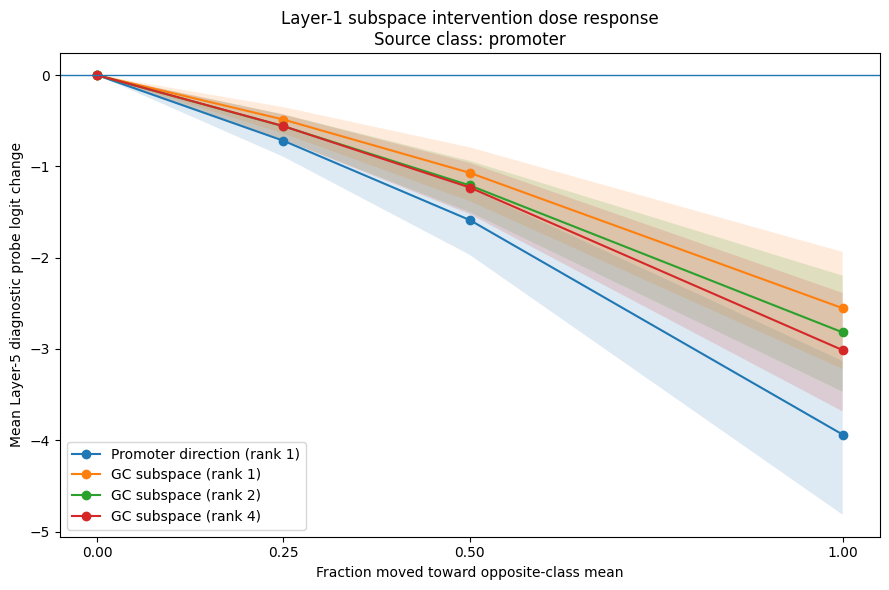

Saved: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/dose_response_promoter.png


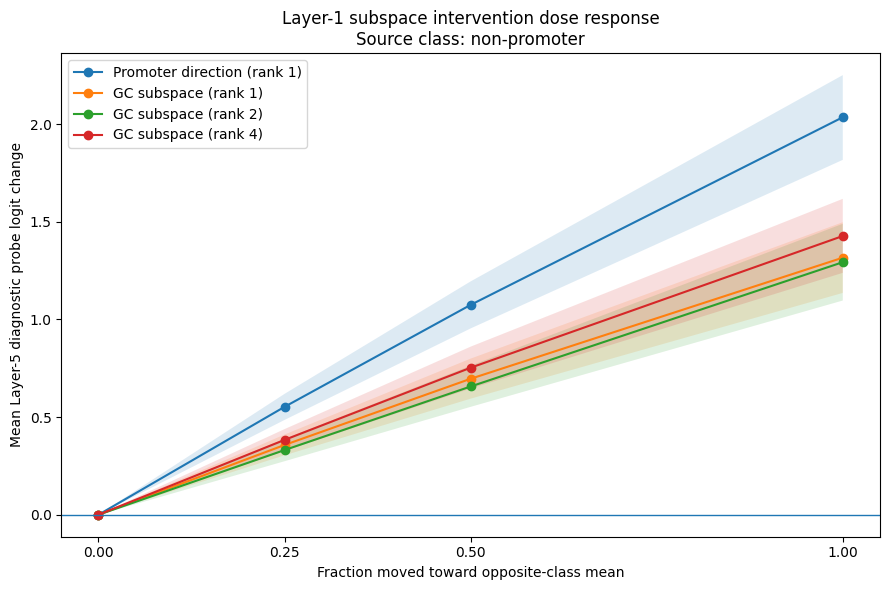

Saved: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/dose_response_non_promoter.png


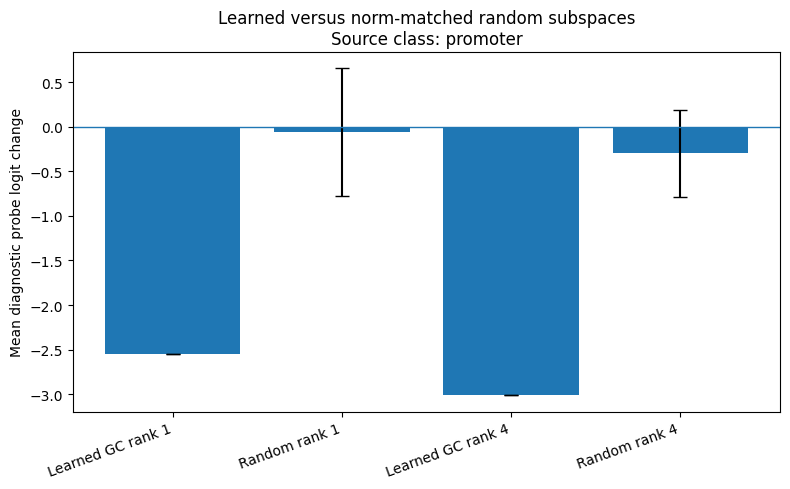

Saved: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/learned_vs_random_promoter.png


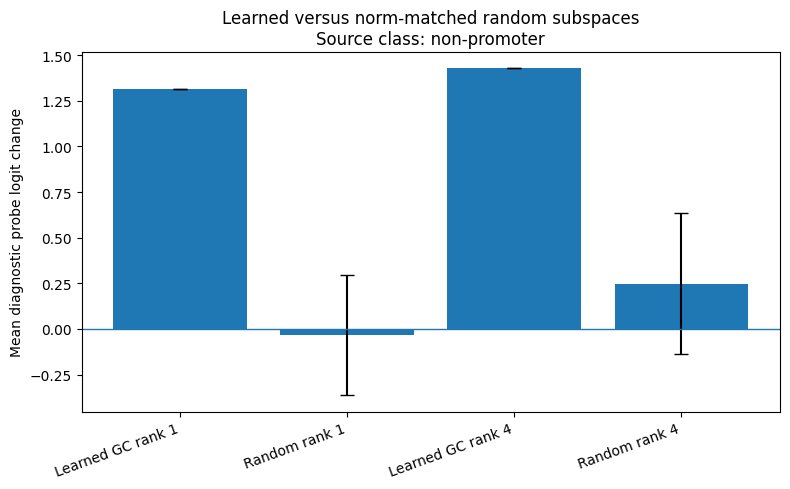

Saved: /content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/learned_vs_random_non_promoter.png
Full-strength prediction-flip summary


,source_class,basis_display_name,number_of_sequences,mean_probe_logit_change,expected_direction_fraction,expected_class_flip_fraction,number_expected_class_flips,mean_intervened_probe_logit
0,non-promoter,GC subspace (rank 1),189,1.316084,0.862434,0.116402,22,-1.939111
1,non-promoter,Promoter direction (rank 1),189,2.035187,0.910053,0.169312,32,-1.220008
2,non-promoter,GC subspace (rank 2),189,1.293029,0.820106,0.105820,20,-1.962167
3,non-promoter,GC subspace (rank 4),189,1.427098,0.835979,0.121693,23,-1.828097
4,promoter,GC subspace (rank 1),189,-2.553317,0.656085,0.116402,22,4.840107
5,promoter,Promoter direction (rank 1),189,-3.937716,0.761905,0.195767,37,3.455709
6,promoter,GC subspace (rank 2),189,-2.818160,0.714286,0.116402,22,4.575264
7,promoter,GC subspace (rank 4),189,-3.012652,0.751323,0.132275,25,4.380772



Notebook 8 final evidence table


,source_class,basis,mean_logit_change,bootstrap_95_ci,expected_direction_percent,expected_flip_percent,clean_separation_fraction_percent
0,non-promoter,GC subspace (rank 1),1.316084,"[1.136, 1.498]",86.243386,11.640212,12.359198
1,non-promoter,Promoter direction (rank 1),2.035187,"[1.817, 2.251]",91.005291,16.931217,19.112214
2,non-promoter,GC subspace (rank 2),1.293029,"[1.097, 1.490]",82.010582,10.582011,12.142690
3,non-promoter,GC subspace (rank 4),1.427098,"[1.239, 1.617]",83.597884,12.169312,13.401722
4,promoter,GC subspace (rank 1),-2.553317,"[-3.220, -1.938]",65.608466,11.640212,23.977915
5,promoter,Promoter direction (rank 1),-3.937716,"[-4.816, -3.133]",76.190476,19.576720,36.978647
6,promoter,GC subspace (rank 2),-2.818160,"[-3.469, -2.197]",71.428571,11.640212,26.465027
7,promoter,GC subspace (rank 4),-3.012652,"[-3.684, -2.386]",75.132275,13.227513,28.291483



Saved:
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/prediction_flip_summary.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/notebook8_final_evidence_table.csv
/content/drive/MyDrive/algoverse/dnabert/outputs/promoter_mlp_subspace_causal_interventions/notebook8_claims_and_limitations.json

Cell 11 complete. Notebook 8 now has its final figures, evidence table, claims, and limitations.


In [15]:
# ------------------------------------------------------------
# Final Notebook 8 figures and evidence summary
# ------------------------------------------------------------

from __future__ import annotations

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Human-readable basis labels
# ------------------------------------------------------------

basis_display_names = {
    "promoter_direction_rank1": "Promoter direction (rank 1)",
    "gc_svd_rank1": "GC subspace (rank 1)",
    "gc_svd_rank2": "GC subspace (rank 2)",
    "gc_svd_rank4": "GC subspace (rank 4)",
}


plot_summary = causal_summary.copy()

plot_summary[
    "basis_display_name"
] = plot_summary[
    "basis_name"
].map(
    basis_display_names
)


# ------------------------------------------------------------
# Figure 1: dose response
# ------------------------------------------------------------

for source_class in [
    "promoter",
    "non-promoter",
]:
    class_plot_data = (
        plot_summary.loc[
            plot_summary[
                "source_class"
            ].eq(source_class)
        ]
        .copy()
    )

    plt.figure(
        figsize=(9, 6)
    )

    for basis_name in [
        "promoter_direction_rank1",
        "gc_svd_rank1",
        "gc_svd_rank2",
        "gc_svd_rank4",
    ]:
        basis_data = (
            class_plot_data.loc[
                class_plot_data[
                    "basis_name"
                ].eq(basis_name)
            ]
            .sort_values(
                "intervention_fraction"
            )
        )

        plt.plot(
            basis_data[
                "intervention_fraction"
            ],
            basis_data[
                "mean_probe_logit_change"
            ],
            marker="o",
            label=basis_display_names[
                basis_name
            ],
        )

        plt.fill_between(
            basis_data[
                "intervention_fraction"
            ],
            basis_data[
                "bootstrap_ci_lower"
            ],
            basis_data[
                "bootstrap_ci_upper"
            ],
            alpha=0.15,
        )

    plt.axhline(
        0.0,
        linewidth=1,
    )

    plt.xlabel(
        "Fraction moved toward opposite-class mean"
    )

    plt.ylabel(
        "Mean Layer-5 diagnostic probe logit change"
    )

    plt.title(
        (
            "Layer-1 subspace intervention dose response\n"
            f"Source class: {source_class}"
        )
    )

    plt.xticks(
        [
            0.0,
            0.25,
            0.50,
            1.00,
        ]
    )

    plt.legend()
    plt.tight_layout()

    figure_path = (
        NOTEBOOK8_DIR
        / (
            f"dose_response_"
            f"{source_class.replace('-', '_')}.png"
        )
    )

    plt.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Saved:",
        figure_path,
    )


# ------------------------------------------------------------
# Figure 2: learned versus random effects
# ------------------------------------------------------------

learned_random_plot_rows = []

for _, row in specificity_summary.iterrows():
    source_class = str(
        row[
            "source_class"
        ]
    )

    learned_basis_name = str(
        row[
            "learned_basis_name"
        ]
    )

    rank = int(
        row[
            "rank"
        ]
    )

    learned_random_plot_rows.append(
        {
            "source_class": source_class,
            "rank": rank,
            "condition": (
                f"Learned GC rank {rank}"
            ),
            "mean_effect": float(
                row[
                    "learned_mean_effect"
                ]
            ),
            "effect_std": 0.0,
        }
    )

    learned_random_plot_rows.append(
        {
            "source_class": source_class,
            "rank": rank,
            "condition": (
                f"Random rank {rank}"
            ),
            "mean_effect": float(
                row[
                    "random_mean_effect"
                ]
            ),
            "effect_std": float(
                row[
                    "random_effect_std"
                ]
            ),
        }
    )


learned_random_plot = pd.DataFrame(
    learned_random_plot_rows
)


for source_class in [
    "promoter",
    "non-promoter",
]:
    class_data = (
        learned_random_plot.loc[
            learned_random_plot[
                "source_class"
            ].eq(source_class)
        ]
        .copy()
    )

    plt.figure(
        figsize=(8, 5)
    )

    x_positions = np.arange(
        len(class_data)
    )

    plt.bar(
        x_positions,
        class_data[
            "mean_effect"
        ],
        yerr=class_data[
            "effect_std"
        ],
        capsize=5,
    )

    plt.axhline(
        0.0,
        linewidth=1,
    )

    plt.xticks(
        x_positions,
        class_data[
            "condition"
        ],
        rotation=20,
        ha="right",
    )

    plt.ylabel(
        "Mean diagnostic probe logit change"
    )

    plt.title(
        (
            "Learned versus norm-matched random subspaces\n"
            f"Source class: {source_class}"
        )
    )

    plt.tight_layout()

    figure_path = (
        NOTEBOOK8_DIR
        / (
            "learned_vs_random_"
            f"{source_class.replace('-', '_')}.png"
        )
    )

    plt.savefig(
        figure_path,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()

    print(
        "Saved:",
        figure_path,
    )


# ------------------------------------------------------------
# Prediction-flip summary
# ------------------------------------------------------------

prediction_flip_summary = (
    full_strength_summary[
        [
            "source_class",
            "basis_name",
            "basis_rank",
            "number_of_sequences",
            "mean_probe_logit_change",
            "expected_direction_fraction",
            "expected_class_flip_fraction",
            "mean_intervened_probe_logit",
        ]
    ]
    .copy()
)

prediction_flip_summary[
    "number_expected_class_flips"
] = np.rint(
    prediction_flip_summary[
        "expected_class_flip_fraction"
    ]
    *
    prediction_flip_summary[
        "number_of_sequences"
    ]
).astype(int)


prediction_flip_summary[
    "basis_display_name"
] = prediction_flip_summary[
    "basis_name"
].map(
    basis_display_names
)


print("=" * 80)
print("Full-strength prediction-flip summary")
print("=" * 80)

display(
    prediction_flip_summary[
        [
            "source_class",
            "basis_display_name",
            "number_of_sequences",
            "mean_probe_logit_change",
            "expected_direction_fraction",
            "expected_class_flip_fraction",
            "number_expected_class_flips",
            "mean_intervened_probe_logit",
        ]
    ]
)


# ------------------------------------------------------------
# Compact evidence table
# ------------------------------------------------------------

evidence_rows = []

for _, row in full_strength_summary.iterrows():
    evidence_rows.append(
        {
            "source_class": str(
                row[
                    "source_class"
                ]
            ),
            "basis": basis_display_names[
                str(
                    row[
                        "basis_name"
                    ]
                )
            ],
            "mean_logit_change": float(
                row[
                    "mean_probe_logit_change"
                ]
            ),
            "bootstrap_95_ci": (
                f"[{float(row['bootstrap_ci_lower']):.3f}, "
                f"{float(row['bootstrap_ci_upper']):.3f}]"
            ),
            "expected_direction_percent": float(
                100.0
                * row[
                    "expected_direction_fraction"
                ]
            ),
            "expected_flip_percent": float(
                100.0
                * row[
                    "expected_class_flip_fraction"
                ]
            ),
            "clean_separation_fraction_percent": float(
                100.0
                * row[
                    "effect_as_fraction_of_clean_separation"
                ]
            ),
        }
    )


final_evidence_table = pd.DataFrame(
    evidence_rows
)


print("\n" + "=" * 80)
print("Notebook 8 final evidence table")
print("=" * 80)

display(
    final_evidence_table
)


# ------------------------------------------------------------
# Final claims and limitations
# ------------------------------------------------------------

notebook8_claims = {
    "primary_claim": (
        "A specific low-dimensional Layer-1 MLP subspace "
        "causally controls a substantial component of "
        "promoter-associated information readable by the "
        "fixed Layer-5 diagnostic probe."
    ),
    "causal_evidence": [
        (
            "Moving Layer-1 MLP coordinates toward the "
            "opposite class produced bidirectional changes "
            "in Layer-5 diagnostic probe logits."
        ),
        (
            "Mean effects increased with intervention "
            "fraction, supporting a dose response."
        ),
        (
            "The promoter direction produced a full-strength "
            "mean change of -3.938 logits for promoters and "
            "+2.035 logits for non-promoters."
        ),
        (
            "The GC rank-4 subspace produced a full-strength "
            "mean change of -3.013 logits for promoters and "
            "+1.427 logits for non-promoters."
        ),
        (
            "Learned GC rank-1 and rank-4 subspaces exceeded "
            "all 20 norm-matched random subspaces for both "
            "source classes."
        ),
    ],
    "specificity_result": {
        "number_of_random_bases_per_rank": 20,
        "empirical_one_sided_p_value": (
            1.0 / 21.0
        ),
        "interpretation": (
            "No sampled random basis matched or exceeded the "
            "corresponding learned GC-subspace effect."
        ),
    },
    "asymmetry": (
        "The subspaces were more effective at reducing "
        "promoter evidence in promoters than at creating "
        "promoter evidence in arbitrary non-promoters."
    ),
    "limitations": [
        (
            "The output is a fixed diagnostic probe, not a "
            "native DNABERT-2 promoter classifier."
        ),
        (
            "Class-conditional coordinate replacement is not "
            "equivalent to strict subspace ablation."
        ),
        (
            "The experiment does not establish a complete "
            "promoter-recognition circuit."
        ),
        (
            "GC association does not prove that the subspace "
            "encodes only GC content."
        ),
        (
            "Twenty random bases limit empirical p-value "
            "resolution to 1/21."
        ),
    ],
}


# ------------------------------------------------------------
# Save final outputs
# ------------------------------------------------------------

PREDICTION_FLIP_SUMMARY_PATH = (
    NOTEBOOK8_DIR
    / "prediction_flip_summary.csv"
)

FINAL_EVIDENCE_TABLE_PATH = (
    NOTEBOOK8_DIR
    / "notebook8_final_evidence_table.csv"
)

FINAL_CLAIMS_PATH = (
    NOTEBOOK8_DIR
    / "notebook8_claims_and_limitations.json"
)


prediction_flip_summary.to_csv(
    PREDICTION_FLIP_SUMMARY_PATH,
    index=False,
)

final_evidence_table.to_csv(
    FINAL_EVIDENCE_TABLE_PATH,
    index=False,
)

with open(
    FINAL_CLAIMS_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        notebook8_claims,
        file,
        indent=2,
    )


print("\nSaved:")
print(PREDICTION_FLIP_SUMMARY_PATH)
print(FINAL_EVIDENCE_TABLE_PATH)
print(FINAL_CLAIMS_PATH)

print(
    "\nCell 11 complete. Notebook 8 now has its final "
    "figures, evidence table, claims, and limitations."
)